# Path Planning for Autonomous Mobile Robots
## Sampling-Based Planning, Evolutionary Techniques and Deep Reinforcement Learning

**AIML ZG528 – Artificial Intelligence and Machine Learning for Robotics**  
**Laboratory 6 & Laboratory 7**

---

### Build Your Warehouse AMR: From Planning to Learning

In the previous laboratories, we progressively developed a simulated warehouse Autonomous Mobile Robot (AMR). The robot can represent its environment, model its motion and sensor behaviour, estimate its location, and use visual information to understand its surroundings.

However, an autonomous robot must do more than perceive its environment. It must also decide **how to move from its current position to a desired destination while avoiding obstacles and satisfying navigation constraints.**

In these laboratories, we extend our warehouse AMR with two important capabilities:

- **Lab 6 – Path Planning:** Explore sampling-based planning using the Rapidly-exploring Random Tree (RRT) algorithm and investigate how evolutionary techniques can improve candidate paths.
- **Lab 7 – Learning-Based Path Planning:** Formulate navigation as a reinforcement learning problem and train an agent to learn goal-directed behaviour through interaction with its environment.

We will use the same warehouse environment and robot developed in the previous laboratories. Our focus is not merely to execute algorithms, but to understand their behaviour, evaluate their performance, and identify the situations in which each approach is useful.

---

**The central engineering question**

*How should a warehouse AMR navigate safely and efficiently through an environment containing obstacles, when a conventional planner or a learned navigation policy is used?*

## 1. Learning Objectives

The following objectives are based on the official laboratory objectives specified in the BITS course handout.

### Lab 6 – Sampling-Based and Evolutionary Path Planning

**Official Laboratory Objective:**

Implement sampling based planner and evolutionary techniques for Path Planning.

By completing this laboratory, students should be able to:

1. Understand how sampling-based methods explore a robot's configuration space to identify collision-free paths.
2. Implement and execute the Rapidly-exploring Random Tree (RRT) algorithm in a simulated warehouse environment.
3. Visualize the exploration process, search tree, and resulting path.
4. Investigate how algorithm parameters influence exploration, computational effort, and path quality.
5. Apply a guided evolutionary optimization activity to candidate paths and examine its effect on path quality.

### Lab 7 – Deep Reinforcement Learning for Path Planning

**Official Laboratory Objective:**

Implement Deep Reinforcement Learning for Path Planning.

By completing this laboratory, students should be able to:

1. Understand how a robot navigation problem can be formulated as an interaction between an agent and an environment.
2. Identify the state representation, available actions, reward structure, and episode termination conditions for a path-planning problem.
3. Implement a Deep Reinforcement Learning approach for goal-directed navigation in a simulated environment.
4. Observe the training process and evaluate the learned navigation behaviour.
5. Examine the strengths and limitations of a learned navigation policy in the warehouse environment.

---

### Overall Engineering Outcome

At the end of these two laboratories, students should be able to distinguish between a path generated through algorithmic search and navigation behaviour learned through interaction, and evaluate their suitability for an autonomous warehouse mobile robot.

## 2. Connection to Previous Laboratories

Throughout the previous five laboratories, we progressively developed the capabilities of our warehouse Autonomous Mobile Robot (AMR).

| Previous Laboratory | Capability Developed |
|---|---|
| Lab 1 – Robotics Framework | Established the Python-based robotics development environment and basic robot representation. |
| Lab 2 – Robot System and Simulation | Created the simulated warehouse environment and introduced the robot's basic operation. |
| Lab 3 – Motion and Sensor Modelling | Implemented AIML models for representing robot motion and sensor behaviour. |
| Lab 4 – Robot Localization | Applied machine learning techniques to estimate the robot's location. |
| Lab 5 – Visual SLAM | Explored visual perception and simultaneous localization and mapping using a CNN-based approach. |

### What capability is still missing?

Our robot can represent its environment, model its motion, estimate its location, and use visual information to understand its surroundings.

But consider the following situation:

A warehouse AMR is currently located near a storage area. It receives a task to reach a workstation on the other side of the warehouse. Several racks and other obstacles lie between its current position and the destination.

**The robot now needs to decide how to reach the destination without colliding with obstacles.**

This introduces the next major capability: **Path Planning**.

### How do Labs 6 and 7 extend our robot?

**Lab 6 – Algorithmic Path Planning**

We will investigate how sampling-based and evolutionary techniques can generate and improve candidate paths through an obstacle-filled environment.

**Lab 7 – Learning-Based Path Planning**

We will investigate how a robot can learn goal-directed navigation behaviour through repeated interaction with its environment using Deep Reinforcement Learning.

### Our Development Progression

Environment and Robot Representation  
↓  
Motion and Sensor Modelling  
↓  
Localization  
↓  
Visual SLAM  
↓  
**Path Planning (Lab 6)**  
↓  
**Learning-Based Path Planning (Lab 7)**

The objective is to progressively extend the capabilities of the same warehouse AMR rather than build a completely new robotic system for each laboratory.

## 3. The Warehouse AMR – Problem Scenario

Consider our differential-drive warehouse AMR operating inside a warehouse containing storage racks and other obstacles.

The robot receives a navigation task:

**Move from its current location to a specified destination without colliding with obstacles.**

### 3.1 Warehouse Environment

We will reuse the warehouse environment developed in Lab 2.

The environment has:

- Warehouse width: 10 m
- Warehouse height: 8 m
- Four rectangular storage-rack obstacles
- Free space through which the robot can navigate

The obstacles are represented numerically using:

`(x, y, width, height)`

This representation allows the planning algorithm to reason about obstacle locations rather than relying only on their visual appearance.

### 3.2 Navigation Task

For our experiment, consider the following navigation task:

| Parameter | Value |
|---|---|
| Start position | (1.0, 1.0) m |
| Goal position | (9.0, 7.0) m |
| Warehouse dimensions | 10 m × 8 m |
| Environment | Static obstacles |
| Planning space | Two-dimensional (x, y) |

The robot must find a collision-free route connecting the start position to the goal position.

### 3.3 What Does the Planner Need to Do?

A path planner must:

1. Represent the available navigation space.
2. Identify locations that are occupied by obstacles.
3. Explore possible routes between the start and goal.
4. Reject paths that intersect obstacles.
5. Produce a collision-free path connecting the start and goal, if one is found.

### 3.4 A Simplification for This Laboratory

To focus on path-planning algorithms, we initially represent the robot as a point moving in a two-dimensional workspace.

The planner therefore searches for a sequence of positions:

`(x₀, y₀) → (x₁, y₁) → ... → (xₙ, yₙ)`

This is a simplified geometric planning model. It does not yet account for the robot's complete footprint, orientation constraints, wheel kinematics, or dynamic obstacles.

In a physical warehouse, the robot has a non-zero footprint. A practical planner must account for this footprint, for example by inflating obstacles or performing robot-footprint collision checking.

We will begin with the simpler point-robot representation and discuss its engineering limitations as we evaluate the resulting paths.

### Think Before Implementation

1. Will the shortest straight-line route from the start to the goal necessarily be collision-free?
2. Why is it insufficient to check only the start and goal positions?
3. If two planners find different collision-free paths, how could we decide which path is better?

Keep these questions in mind as we implement and evaluate the planning algorithms.

## 4. Visualizing the Planning Problem

Before implementing a path-planning algorithm, let us visualize the environment in which our warehouse AMR must navigate.

We will use the warehouse dimensions and obstacle representation introduced in Lab 2.

The visualization will show:

- The warehouse boundary.
- The four rectangular storage-rack obstacles.
- The robot's starting position.
- The desired goal position.
- The straight-line connection between the start and goal.

The straight-line connection is shown only as a reference. It is not necessarily a valid path because it may intersect obstacles.

### Observe the Environment

Pay attention to the available free space between the obstacles.

Consider the following:

1. Which obstacles obstruct the direct route?
2. Are there multiple possible routes to the goal?
3. Would a planner need to explore the environment to discover a feasible route?

We will use this same environment for both the sampling-based planner and the learning-based planner.

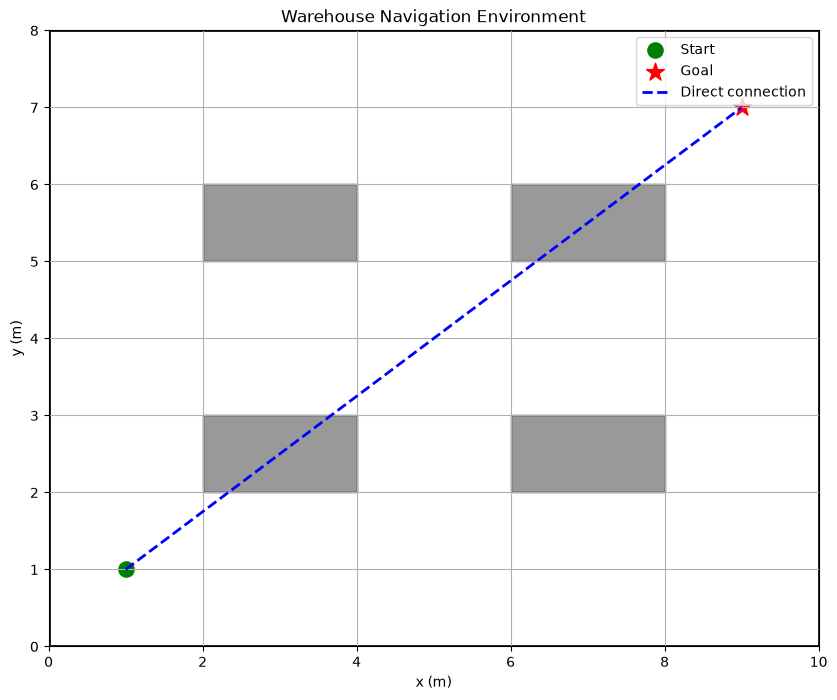

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# --------------------------------------------------
# 1. Warehouse environment
# --------------------------------------------------

warehouse_width = 10.0
warehouse_height = 8.0

# Rectangular obstacles: (x, y, width, height)
obstacles = [
    (2.0, 5.0, 2.0, 1.0),
    (6.0, 5.0, 2.0, 1.0),
    (2.0, 2.0, 2.0, 1.0),
    (6.0, 2.0, 2.0, 1.0)
]

# --------------------------------------------------
# 2. Navigation task
# --------------------------------------------------

start = (1.0, 1.0)
goal = (9.0, 7.0)

# --------------------------------------------------
# 3. Visualize the warehouse
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

# Warehouse boundary
ax.add_patch(
    Rectangle(
        (0, 0),
        warehouse_width,
        warehouse_height,
        fill=False,
        linewidth=2
    )
)

# Draw obstacles
for x, y, width, height in obstacles:
    ax.add_patch(
        Rectangle(
            (x, y),
            width,
            height,
            facecolor="grey",
            edgecolor="black",
            alpha=0.8
        )
    )

# Start position
ax.scatter(
    *start,
    color="green",
    marker="o",
    s=120,
    label="Start"
)

# Goal position
ax.scatter(
    *goal,
    color="red",
    marker="*",
    s=180,
    label="Goal"
)

# Direct reference connection
ax.plot(
    [start[0], goal[0]],
    [start[1], goal[1]],
    linestyle="--",
    color="blue",
    linewidth=2,
    label="Direct connection"
)

ax.set_xlim(0, warehouse_width)
ax.set_ylim(0, warehouse_height)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Warehouse Navigation Environment")
ax.legend()
ax.grid(True)

plt.show()

## 5. Understanding the Path-Planning Problem

Our warehouse AMR has a starting position and a destination. However, it cannot simply move along the straight line connecting these two positions because obstacles may block its route.

**Path planning is the process of finding a feasible route from a specified start configuration to a goal configuration while satisfying environmental constraints such as obstacle avoidance.**

For our current experiment, the planner operates in a two-dimensional workspace.

### 5.1 Three Important Elements

**1. Start Position**

The initial location from which the robot begins its navigation task.

For our experiment:

(1, 1)

**2. Goal Position**

The desired destination that the robot must reach.

For our experiment:

(9, 7)

**3. Obstacles**

Objects that occupy portions of the workspace and cannot be traversed by the robot.

Our planner must identify routes that avoid these occupied regions.

### 5.2 What Does a Feasible Path Mean?

A feasible path must:

- Begin at the specified start position.
- Reach the specified goal position.
- Remain within the warehouse boundaries.
- Avoid collisions with obstacles.

A feasible path is not necessarily the shortest path or the smoothest path.

These are separate path-quality considerations that we will investigate later.

### 5.3 Path Planning as a Search Problem

Imagine generating several possible routes between the start and goal.

Some routes may intersect obstacles and must be rejected. Others may avoid all obstacles and can be considered feasible candidates.

The challenge is to discover a feasible route efficiently in an environment where the available free space may be complex.

In the next section, we will examine how a sampling-based planner addresses this problem by exploring positions in the workspace.

## 6. Workspace, Obstacle Space and Free Space

The warehouse environment contains both regions that the robot can occupy and regions that it must avoid.

To understand how a path planner operates, we distinguish between three concepts.

### 6.1 Workspace

The **workspace** represents the physical region in which the robot operates.

For our experiment, the workspace is a two-dimensional rectangular region:

0 ≤ x ≤ 10

0 ≤ y ≤ 8

Every candidate robot position must lie within these boundaries.

### 6.2 Obstacle Space

The **obstacle space** consists of regions occupied by obstacles.

In our warehouse, each storage rack is represented by a rectangle:

(x, y, width, height)

A candidate position inside an obstacle region is invalid because it represents a collision.

### 6.3 Free Space

The **free space** is the portion of the workspace that is not occupied by obstacles.

Mathematically:

Free Space = Workspace − Obstacle Space

The planner must search for a route that remains inside the free space.

### 6.4 Why Is This Distinction Important?

A path planner does not simply connect two points.

It must determine whether candidate positions and the connections between them are valid.

For example:

- A point may lie inside the warehouse but also inside a storage rack.
- Two points may both lie in free space, but the straight-line segment connecting them may cross an obstacle.
- A route may avoid obstacles but extend outside the warehouse boundary.

Therefore, collision checking must consider both individual positions and the path segments connecting them.

**Engineering takeaway:** A valid path requires more than collision-free endpoints. The entire path must satisfy the environmental constraints.

### Think Before Coding

Consider two candidate robot positions, A and B.

Both positions lie in free space. However, the straight-line segment joining A and B passes through a storage rack.

**Question:** Can the planner accept the connection between A and B?

Think about the difference between checking whether a position is valid and checking whether a motion between two positions is valid.

We will implement both checks before developing the RRT algorithm.

## 7. Implementing Collision Checking

A path planner repeatedly evaluates candidate positions and connections. We therefore need a systematic way to determine whether a position or a motion is valid.

We will implement two collision-checking operations.

### 7.1 Point Collision Checking

Given a candidate position (x, y), determine whether:

1. It lies within the warehouse boundaries.
2. It lies outside every obstacle.

The function will return:

- `True` if the position is collision-free.
- `False` if the position is outside the workspace or inside/on an obstacle.

### 7.2 Path Segment Collision Checking

Checking two endpoints independently does not guarantee that the motion between them is collision-free.

Consider a straight-line segment connecting positions A and B. The segment may pass through an obstacle even when both endpoints are in free space.

We therefore need to check the entire segment against every obstacle.

For this implementation, we will use a geometric line-segment–rectangle intersection test. This is preferable to checking a few sampled points along the segment because sparse sampling can miss a collision.

**Boundary convention:** Touching an obstacle boundary is treated as a collision. The warehouse outer boundary, however, is considered navigable.

### 7.3 Functions We Will Implement

| Function | Purpose |
|---|---|
| `is_point_collision_free()` | Checks whether a single position is valid. |
| `is_path_collision_free()` | Checks whether the complete straight-line connection is valid. |

These functions will be reused throughout Lab 6.

In [3]:
def is_point_collision_free(point):
    """
    Check whether a point lies inside the warehouse
    and outside all obstacles.

    Returns:
        True  - collision-free
        False - outside workspace or colliding
    """

    x, y = point

    # Check warehouse boundaries
    if not (0 <= x <= warehouse_width and
            0 <= y <= warehouse_height):
        return False

    # Check obstacle occupancy
    for ox, oy, width, height in obstacles:

        if (ox <= x <= ox + width and
            oy <= y <= oy + height):
            return False

    return True


def segment_intersects_rectangle(p1, p2, rectangle):
    """
    Check whether a line segment intersects a rectangle.

    Uses the Liang-Barsky line clipping algorithm.

    Boundary contact is treated as an intersection.
    """

    x1, y1 = p1
    x2, y2 = p2

    ox, oy, width, height = rectangle

    xmin, xmax = ox, ox + width
    ymin, ymax = oy, oy + height

    dx = x2 - x1
    dy = y2 - y1

    p_values = [-dx, dx, -dy, dy]
    q_values = [
        x1 - xmin,
        xmax - x1,
        y1 - ymin,
        ymax - y1
    ]

    t_enter = 0.0
    t_exit = 1.0

    for p, q in zip(p_values, q_values):

        # Segment is parallel to this rectangle boundary
        if p == 0:

            if q < 0:
                return False

        else:

            t = q / p

            if p < 0:
                t_enter = max(t_enter, t)
            else:
                t_exit = min(t_exit, t)

            if t_enter > t_exit:
                return False

    return True


def is_path_collision_free(p1, p2):
    """
    Check whether the complete straight-line segment
    between p1 and p2 is collision-free.

    Returns:
        True  - valid connection
        False - invalid connection
    """

    # Both endpoints must be valid
    if not is_point_collision_free(p1):
        return False

    if not is_point_collision_free(p2):
        return False

    # Check intersection with every obstacle
    for obstacle in obstacles:

        if segment_intersects_rectangle(p1, p2, obstacle):
            return False

    return True

In [4]:
# Test 1: A point in free space
print("Free-space point:",
      is_point_collision_free((1.0, 1.0)))

# Test 2: A point inside an obstacle
print("Obstacle point:",
      is_point_collision_free((3.0, 5.5)))

# Test 3: A point outside the warehouse
print("Outside warehouse:",
      is_point_collision_free((11.0, 5.0)))

# Test 4: A collision-free connection
print("Free connection:",
      is_path_collision_free((1.0, 1.0), (1.0, 4.0)))

# Test 5: A connection passing through an obstacle
print("Obstacle-crossing connection:",
      is_path_collision_free((1.0, 5.5), (5.0, 5.5)))

Free-space point: True
Obstacle point: False
Outside warehouse: False
Free connection: True
Obstacle-crossing connection: False


### Engineering Observation

The collision-checking functions distinguish between two different situations:

- A position is valid when the robot can occupy that location.
- A connection is valid when the complete straight-line motion between two positions avoids obstacles.

Notice that two valid positions do not necessarily have a valid connection between them.

This distinction is essential for sampling-based planners because they construct paths by repeatedly connecting newly sampled positions to existing tree nodes.

**Checkpoint:** Why would an RRT implementation that checks only sampled points, but not the edges connecting them, potentially generate an invalid path?

## 8. Sampling-Based Path Planning

Consider our warehouse environment again.

The robot must travel from (1, 1) to (9, 7), avoiding four storage racks.

One possible approach is to examine every possible position in the warehouse and construct a complete representation of all possible connections. However, this can become computationally expensive, particularly in high-dimensional configuration spaces.

**Sampling-based planners address this challenge by exploring selected configurations rather than explicitly examining the entire space.**

### 8.1 What Is Sampling?

Sampling is the process of selecting candidate positions from the robot's configuration space.

For our current two-dimensional planning problem, a sampled configuration is simply a position:

(x, y)

For example:

- Sample 1: (3.5, 4.2)
- Sample 2: (7.1, 3.8)
- Sample 3: (5.2, 6.5)

Each sampled position is checked to determine whether it is valid.

The planner uses these samples to progressively explore the available space and identify possible connections between locations.

### 8.2 How Does Sampling Help?

Instead of constructing every possible route, the planner explores a limited number of candidate configurations.

This offers an important advantage:

The computational effort can be concentrated on exploring regions that may help connect the start and goal.

However, sampling does not automatically guarantee that a feasible path will be found within a finite number of iterations. The result depends on the algorithm, environment, sampling strategy and computational budget.

### 8.3 Sampling-Based Planning Methods

Some commonly used sampling-based planning approaches include:

- **Probabilistic Roadmap (PRM):** Samples configurations and connects nearby collision-free configurations to construct a roadmap.
- **Rapidly-exploring Random Tree (RRT):** Builds a tree by repeatedly sampling configurations and extending the existing tree towards selected samples.
- **RRT\*:** An extension of RRT that progressively improves path cost through rewiring, under suitable conditions.

### 8.4 Our Approach

In this laboratory, we will focus on the **Rapidly-exploring Random Tree (RRT)** algorithm.

RRT is particularly useful for understanding how a planner can explore a continuous configuration space using incremental tree expansion.

We will first implement basic RRT, observe how its search tree develops, and examine how it finds a collision-free connection between the start and goal.

**Important:** Basic RRT aims to find a feasible path. It does not guarantee that the first path found is the shortest or optimal path.

## How Does RRT Explore the Warehouse?

**Rapidly-exploring Random Tree (RRT)** is a sampling-based path-planning algorithm that progressively builds a tree of collision-free connections, starting from the robot's initial position.

Instead of generating an entire path in one attempt, RRT expands a connected tree until it finds a feasible connection to the goal.

### How Does the Algorithm Work?

Consider the warehouse environment established in the previous cells.

1. **Initialize the tree:** Place the root node at the robot's starting position, `(1, 1)`.

2. **Generate a random sample:** Select a candidate position from the warehouse's configuration space.

3. **Find the nearest node:** Identify the existing tree node closest to the random sample.

4. **Steer towards the sample:** Move from the nearest node towards the sample by a fixed step length. This generates a new candidate node.

5. **Check for collision:** Verify that the candidate node and the connecting line segment are collision-free.

6. **Expand the tree:** If the connection is valid, add the new node and its parent relationship to the tree.

7. **Check for the goal:** If the new node is sufficiently close to the goal and a collision-free connection exists, connect the tree to the goal.

8. **Extract the path:** Trace the parent relationships backwards from the goal to the starting position.

### Understanding the Exploration Process

The important distinction is that **random samples guide exploration, but only collision-free connections become part of the tree**.

### What Does the Tree Represent?

- **Nodes:** Valid robot positions explored by the planner.
- **Edges:** Collision-free connections between positions.
- **Root:** The robot's starting position.
- **Goal connection:** The final connection that completes a feasible route.

### Engineering Observation

RRT is useful in environments where explicitly searching the entire configuration space is difficult. Random sampling helps the tree explore different regions, while incremental expansion ensures that every accepted node remains connected to the starting position.

However, a feasible RRT path is not necessarily the shortest or smoothest path. We will examine path quality after implementing the planner.

### Checkpoint

Before proceeding, consider this question:

**Why does RRT find the nearest existing tree node before generating a new connection?**

## Representing the RRT Tree in Python

Before implementing RRT, we need a way to represent the tree being constructed by the planner.

Recall that an RRT tree consists of:
- Nodes representing valid positions in the warehouse.
- Edges connecting collision-free positions.
- A root node corresponding to the robot's starting position.
- Parent relationships that preserve the connectivity of the tree.

### How Should We Store the Tree?

We will use two Python lists:

1. **`rrt_nodes`** – stores the coordinates of every node added to the tree.
2. **`rrt_parents`** – stores the index of the parent node for each corresponding node.

Each node is represented by a two-dimensional coordinate:

\[
q_i = (x_i, y_i)
\]

The parent list stores the index of the node from which the current node was generated.

For example:

| Node index | Coordinates | Parent index |
|---|---|---|
| 0 | (1.0, 1.0) | None |
| 1 | (1.5, 1.2) | 0 |
| 2 | (2.0, 1.5) | 1 |
| 3 | (1.8, 2.0) | 1 |

Here, node 0 is the root. Nodes 1, 2 and 3 are connected through their respective parent relationships.

### Why Store Parent Indices?

When the planner reaches the goal, it does not need to search through every possible combination of edges to reconstruct the path.

Instead, it starts at the goal node and repeatedly follows the parent index until it reaches the root.

This provides an efficient way to recover the route discovered by RRT.

### Important Design Decision

The first node in the tree will always be the starting position:

\[
q_0 = (1,1)
\]

Its parent will be `None`, because the root has no parent.

In the next cell, we will initialize these data structures and verify that the tree begins at the correct position.

In [5]:
# Initialize the RRT tree

rrt_nodes = [np.array(start, dtype=float)]
rrt_parents = [None]

print("RRT tree initialized.")
print("Number of nodes:", len(rrt_nodes))
print("Root node:", rrt_nodes[0])
print("Parent of root:", rrt_parents[0])

RRT tree initialized.
Number of nodes: 1
Root node: [1. 1.]
Parent of root: None


## Finding the Nearest Node

RRT does not connect a random sample directly to the tree. First, it identifies the existing tree node that is closest to the sampled position.

This is important because every new node must extend the existing tree while maintaining connectivity with the starting position.

### How Do We Measure Distance?

Since our robot is represented by a point in a two-dimensional workspace, we use Euclidean distance.

For two positions:

\[
q_1 = (x_1,y_1), \qquad q_2 = (x_2,y_2)
\]

The Euclidean distance is:

\[
d(q_1,q_2) =
\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}
\]

### Example

Suppose the tree contains three nodes:

- Node 0: (1, 1)
- Node 1: (3, 2)
- Node 2: (5, 4)

A random sample is generated at (4, 3).

The planner calculates the distance from the sample to every existing node and selects the node with the smallest distance.

This selected node becomes the starting point for the next expansion.

### Engineering Observation

The nearest-node operation determines where the tree expands from. It does not determine whether the new connection is collision-free. Collision checking will be performed separately before accepting a new node.

In [6]:
def find_nearest_node(sample, nodes):
    """
    Find the index of the tree node closest to a sampled position.

    Parameters:
        sample: Randomly sampled position (x, y).
        nodes: List of existing RRT nodes.

    Returns:
        Index of the nearest node.
    """
    distances = [
        np.linalg.norm(node - sample)
        for node in nodes
    ]

    return int(np.argmin(distances))


# Test the nearest-node operation
test_nodes = [
    np.array([1.0, 1.0]),
    np.array([3.0, 2.0]),
    np.array([5.0, 4.0])
]

test_sample = np.array([4.0, 3.0])

nearest_index = find_nearest_node(test_sample, test_nodes)

print("Sample position:", test_sample)
print("Nearest node index:", nearest_index)
print("Nearest node position:", test_nodes[nearest_index])
print("Distance:", np.linalg.norm(test_nodes[nearest_index] - test_sample))

Sample position: [4. 3.]
Nearest node index: 1
Nearest node position: [3. 2.]
Distance: 1.4142135623730951


## Steering Towards a Random Sample

Once RRT identifies the nearest existing node, it generates a new candidate position in the direction of the random sample.

This operation is called **steering**.

### Why Do We Need Steering?

A random sample may be located far away from the nearest tree node. Connecting directly to that sample could produce unnecessarily long edges and make the exploration process less controlled.

Instead, RRT limits the distance travelled during each expansion using a parameter called the **step length**.

### How Does Steering Work?

Let:

- $q_{\text{near}}$ be the nearest existing tree node.
- $q_{\text{rand}}$ be the randomly sampled position.
- $\eta$ be the maximum step length.

First, calculate the direction from the nearest node towards the sample:

$$
\Delta q = q_{\text{rand}} - q_{\text{near}}
$$

Calculate the distance:

$$
d = \|\Delta q\|
$$

The new candidate position is:

$$
q_{\text{new}} =
q_{\text{near}} +
\min\left(1,\frac{\eta}{d}\right)\Delta q
$$

This ensures that:

- If the sample is farther than the step length, the new node is placed exactly one step length away.
- If the sample is closer than the step length, the new node is placed at the sampled position.

### Example

Suppose:

- Nearest node: (2, 2)
- Random sample: (6, 5)
- Step length: 1.5 m

The distance to the sample is 5 m.

Therefore, RRT moves only 1.5 m towards the sample rather than connecting directly to it.

### Engineering Observation

The step length controls the granularity of tree expansion.

- A small step length produces shorter connections and finer exploration, but may require more iterations.
- A large step length can expand the tree faster, but may make it harder to navigate through narrow passages.

Steering only generates a candidate node. It does not establish that the connection is valid. Collision checking is still required before the node can be added to the tree.

In [7]:
def steer_towards(nearest_node, sample, step_size):
    """
    Generate a new candidate node in the direction of a sample.

    Parameters:
        nearest_node: Coordinates of the nearest existing tree node.
        sample: Randomly sampled position.
        step_size: Maximum distance for one tree expansion.

    Returns:
        New candidate position as a NumPy array.
    """
    direction = sample - nearest_node
    distance = np.linalg.norm(direction)

    if distance == 0:
        return nearest_node.copy()

    travel_distance = min(step_size, distance)

    new_node = nearest_node + (travel_distance / distance) * direction

    return new_node


# Test the steering operation
nearest_node = np.array([2.0, 2.0])
random_sample = np.array([6.0, 5.0])
step_size = 1.5

new_candidate = steer_towards(
    nearest_node,
    random_sample,
    step_size
)

print("Nearest node:", nearest_node)
print("Random sample:", random_sample)
print("Step size:", step_size)
print("New candidate:", new_candidate)
print("Actual movement:", np.linalg.norm(new_candidate - nearest_node))

Nearest node: [2. 2.]
Random sample: [6. 5.]
Step size: 1.5
New candidate: [3.2 2.9]
Actual movement: 1.5


## Validating a New RRT Connection

The steering operation generates a candidate node, but this node cannot be added to the tree immediately.

The planner must first verify that the new connection does not intersect any obstacle.

Consider the following sequence:

1. Select the nearest existing tree node.
2. Generate a candidate node using the steering function.
3. Check whether the candidate lies inside the warehouse boundaries.
4. Check whether the line segment connecting the nearest node and candidate intersects an obstacle.
5. Add the candidate to the tree only if both checks succeed.

We already implemented the required collision-checking functions:

- `is_point_collision_free()` checks whether a position is valid.
- `is_path_collision_free()` checks whether the connection between two positions is valid.

### The Acceptance Condition

A candidate node is accepted only when:

$$
\text{Valid Connection} =
\text{Valid Candidate Position}
\land
\text{Collision-Free Edge}
$$

If either condition fails, the candidate is rejected.

### Why Is This Important?

Imagine that the nearest node is located on one side of a warehouse rack and the candidate is generated on the other side.

Both positions may be valid, but the connecting segment may pass directly through the rack.

Accepting such a connection would introduce an invalid edge into the RRT tree.

**Engineering principle:** Every node added to the RRT tree must be connected to its parent through a collision-free edge.

In [8]:
def expand_rrt_tree(sample, nodes, parents, step_size):
    """
    Attempt one RRT tree expansion.

    Returns:
        True if a new node is successfully added.
        False if the candidate connection is invalid.
    """

    # Step 1: Find the nearest existing node
    nearest_index = find_nearest_node(sample, nodes)
    nearest_node = nodes[nearest_index]

    # Step 2: Generate a candidate using the steering function
    candidate = steer_towards(nearest_node, sample, step_size)

    # Step 3: Check candidate position and connecting edge
    if not is_point_collision_free(candidate):
        return False

    if not is_path_collision_free(nearest_node, candidate):
        return False

    # Step 4: Add the candidate and record its parent
    nodes.append(candidate)
    parents.append(nearest_index)

    return True


# Test one expansion using temporary tree data.
# The actual RRT tree remains unchanged.

test_rrt_nodes = [np.array(start, dtype=float)]
test_rrt_parents = [None]

test_sample = np.array([4.0, 3.0])

accepted = expand_rrt_tree(
    test_sample,
    test_rrt_nodes,
    test_rrt_parents,
    step_size=1.5
)

print("Candidate accepted:", accepted)
print("Number of nodes:", len(test_rrt_nodes))
print("New node:", test_rrt_nodes[-1])
print("Parent index:", test_rrt_parents[-1])

Candidate accepted: True
Number of nodes: 2
New node: [2.24807544 1.83205029]
Parent index: 0


## Visualizing the First RRT Expansion

We have now implemented the basic operations required for one RRT expansion:

1. Finding the nearest existing node.
2. Steering towards a random sample.
3. Checking the candidate position.
4. Validating the connecting edge.
5. Adding the candidate to the tree if the connection is collision-free.

Let us visualize the result of one successful expansion.

### What Should We Observe?

The visualization will show:

- **Green marker:** Starting position (root node).
- **Blue marker:** Newly added RRT node.
- **Line connecting the nodes:** The accepted tree edge.
- **Red marker:** Goal position.
- **Grey rectangles:** Warehouse obstacles.

At this stage, the tree contains only two nodes: the starting position and one newly accepted node.

### Engineering Observation

A single expansion does not produce a complete path to the goal. It only extends the existing tree by one valid connection.

Repeated expansions allow RRT to explore different regions of the warehouse until a feasible connection to the goal is found.

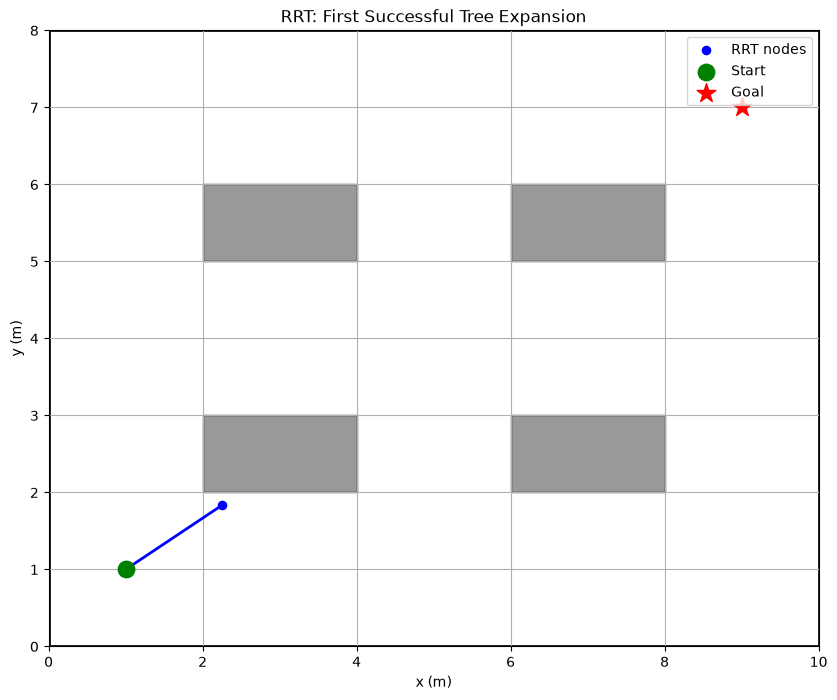

In [9]:
def plot_rrt_tree(nodes, parents, title="RRT Tree"):
    """
    Visualize the current RRT tree in the warehouse.
    """

    fig, ax = plt.subplots(figsize=(10, 8))

    # Draw warehouse boundary
    ax.add_patch(
        Rectangle(
            (0, 0),
            warehouse_width,
            warehouse_height,
            fill=False,
            linewidth=2
        )
    )

    # Draw obstacles
    for x, y, width, height in obstacles:
        ax.add_patch(
            Rectangle(
                (x, y),
                width,
                height,
                facecolor="grey",
                edgecolor="black",
                alpha=0.8
            )
        )

    # Draw tree edges
    for node_index, parent_index in enumerate(parents):
        if parent_index is not None:
            parent = nodes[parent_index]
            node = nodes[node_index]

            ax.plot(
                [parent[0], node[0]],
                [parent[1], node[1]],
                color="blue",
                linewidth=2
            )

    # Draw tree nodes
    node_positions = np.array(nodes)

    ax.scatter(
        node_positions[:, 0],
        node_positions[:, 1],
        color="blue",
        s=35,
        label="RRT nodes",
        zorder=3
    )

    # Draw start and goal
    ax.scatter(*start, color="green", marker="o",
               s=140, label="Start", zorder=4)

    ax.scatter(*goal, color="red", marker="*",
               s=200, label="Goal", zorder=4)

    ax.set_xlim(0, warehouse_width)
    ax.set_ylim(0, warehouse_height)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

    plt.show()


# Visualize the first successful expansion
plot_rrt_tree(
    test_rrt_nodes,
    test_rrt_parents,
    title="RRT: First Successful Tree Expansion"
)

## From One Expansion to the Complete RRT Algorithm

So far, we have implemented and tested the individual operations of RRT:

- Nearest-node search
- Steering towards a random sample
- Collision checking
- Tree expansion
- Tree visualization

We can now combine these operations into a complete path-planning algorithm.

### What Changes in the Complete Algorithm?

Instead of manually providing one random sample, the planner will repeatedly generate samples and attempt to expand the tree.

The process continues until one of two conditions is met:

1. **Goal reached:** The tree reaches a node from which the goal can be connected through a collision-free edge.
2. **Iteration limit reached:** The planner stops after a predefined maximum number of attempts.

### Parameters of the RRT Planner

We will introduce the following parameters:

| Parameter | Purpose |
|---|---|
| `max_iterations` | Maximum number of tree expansion attempts |
| `step_size` | Maximum distance for each expansion |
| `goal_threshold` | Distance within which the planner attempts to connect to the goal |
| `goal_sample_rate` | Probability of directly sampling the goal |

### Why Introduce Goal Bias?

Purely random sampling may spend considerable time exploring regions that do not help the planner reach the destination.

Goal bias addresses this by occasionally selecting the goal itself as the random sample.

For example, a goal sample rate of 0.10 means that approximately 10% of sampling attempts will select the goal directly, while the remaining attempts use random positions in the warehouse.

Goal bias encourages progress towards the destination, but does not guarantee that a solution will be found.

### What Happens When the Goal Is Reached?

When a newly generated node comes within the goal threshold, the planner checks whether the goal can be connected to that node without collision.

If the connection is valid, the goal is added as the final node in the tree.

The planner can then reconstruct the complete path by following parent indices from the goal back to the root.

### Important Distinction

RRT is a probabilistic sampling-based planner. Its success depends on the sampling process, environment geometry and available iterations.

Finding a feasible path does not imply that the path is optimal. Basic RRT does not guarantee the shortest path.

In [10]:
def reconstruct_rrt_path(nodes, parents, goal_index):
    """
    Reconstruct the path by following parent indices
    from the goal node back to the root.
    """
    path = []
    current_index = goal_index

    while current_index is not None:
        path.append(nodes[current_index])
        current_index = parents[current_index]

    return path[::-1]


def rrt_planner(
    start,
    goal,
    max_iterations=5000,
    step_size=0.5,
    goal_threshold=0.5,
    goal_sample_rate=0.10,
    random_seed=42
):
    """
    Implement Rapidly-exploring Random Tree (RRT).

    Returns:
        path: List of coordinates if a path is found, otherwise None.
        nodes: All nodes explored by the planner.
        parents: Parent index of each node.
        success: Whether a feasible path was found.
        iterations: Number of sampling attempts performed.
    """

    rng = np.random.default_rng(random_seed)

    # Initialize the tree
    nodes = [np.array(start, dtype=float)]
    parents = [None]

    if not is_point_collision_free(start):
        raise ValueError("Start position is invalid.")

    if not is_point_collision_free(goal):
        raise ValueError("Goal position is invalid.")

    goal = np.array(goal, dtype=float)

    for iteration in range(1, max_iterations + 1):

        # Step 1: Generate a random sample with goal bias
        if rng.random() < goal_sample_rate:
            sample = goal.copy()
        else:
            sample = np.array([
                rng.uniform(0, warehouse_width),
                rng.uniform(0, warehouse_height)
            ])

        # Step 2: Attempt one tree expansion
        previous_node_count = len(nodes)

        accepted = expand_rrt_tree(
            sample,
            nodes,
            parents,
            step_size
        )

        # Step 3: Check whether a new node was added
        if not accepted:
            continue

        new_node_index = previous_node_count
        new_node = nodes[new_node_index]

        # Step 4: Check whether the goal can be connected
        distance_to_goal = np.linalg.norm(new_node - goal)

        if distance_to_goal <= goal_threshold:
            if is_path_collision_free(new_node, goal):

                # Add the goal as the final tree node
                nodes.append(goal.copy())
                parents.append(new_node_index)

                # Reconstruct the complete path
                path = reconstruct_rrt_path(
                    nodes,
                    parents,
                    len(nodes) - 1
                )

                return path, nodes, parents, True, iteration

    # No feasible path found within the iteration limit
    return None, nodes, parents, False, max_iterations


# Run the RRT planner
rrt_path, rrt_nodes, rrt_parents, rrt_success, rrt_iterations = rrt_planner(
    start=start,
    goal=goal,
    max_iterations=5000,
    step_size=0.5,
    goal_threshold=0.5,
    goal_sample_rate=0.10,
    random_seed=42
)

print("RRT planning completed.")
print("Path found:", rrt_success)
print("Iterations:", rrt_iterations)
print("Total tree nodes:", len(rrt_nodes))

if rrt_success:
    print("Number of path points:", len(rrt_path))
    print("Start position:", rrt_path[0])
    print("Goal position:", rrt_path[-1])
else:
    print("No feasible path found within the iteration limit.")

RRT planning completed.
Path found: True
Iterations: 96
Total tree nodes: 84
Number of path points: 29
Start position: [1. 1.]
Goal position: [9. 7.]


## Visualizing the Complete RRT Solution

The RRT planner has successfully found a feasible path from the warehouse robot's starting position to its destination.

However, the final path alone does not show how the planner explored the environment.

We will visualize two important outputs:

1. **Exploration tree:** All valid nodes and collision-free connections generated during planning.
2. **Final path:** The sequence of connected positions extracted from the tree that leads from the start to the goal.

### Understanding the Visualization

- **Blue lines and nodes:** Explored RRT tree.
- **Green marker:** Starting position.
- **Red marker:** Goal position.
- **Orange line:** Final path extracted by the planner.
- **Grey rectangles:** Warehouse obstacles.

### Observe the Difference

The RRT tree represents the planner's exploration process. It may contain many branches that do not contribute to the final solution.

The final path represents only the sequence of nodes connecting the start to the goal.

This distinction is important: **the exploration tree is not the same as the final navigation path.**

### Engineering Observation

RRT has found a feasible route, but the route may contain unnecessary turns and detours.

In the following activities, we will examine path quality and investigate how the route can be improved.

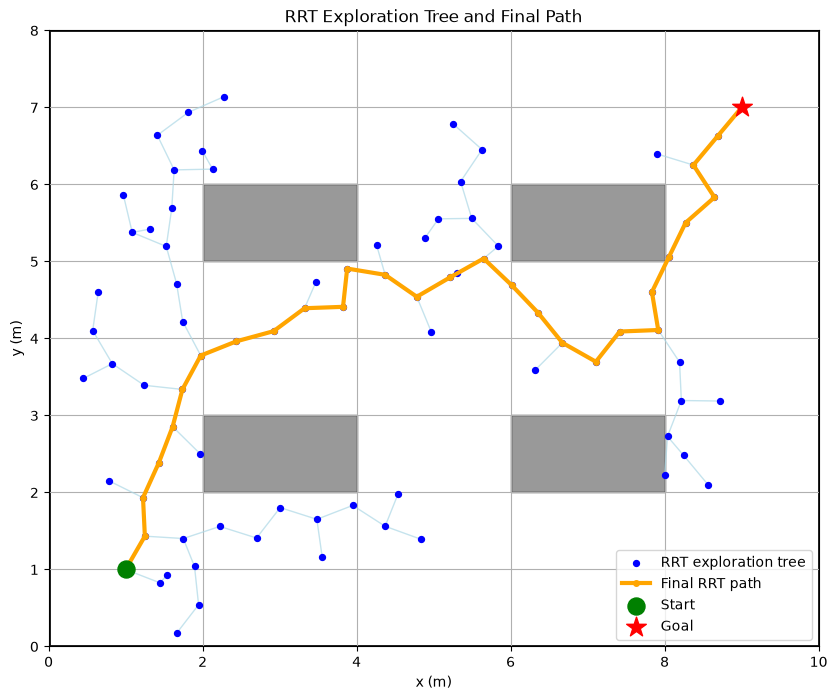

In [11]:
# Visualize the complete RRT exploration tree and final path

fig, ax = plt.subplots(figsize=(10, 8))

# Draw warehouse boundary
ax.add_patch(
    Rectangle(
        (0, 0),
        warehouse_width,
        warehouse_height,
        fill=False,
        linewidth=2
    )
)

# Draw obstacles
for x, y, width, height in obstacles:
    ax.add_patch(
        Rectangle(
            (x, y),
            width,
            height,
            facecolor="grey",
            edgecolor="black",
            alpha=0.8
        )
    )

# Draw all RRT tree edges
for node_index, parent_index in enumerate(rrt_parents):
    if parent_index is not None:
        parent = rrt_nodes[parent_index]
        node = rrt_nodes[node_index]

        ax.plot(
            [parent[0], node[0]],
            [parent[1], node[1]],
            color="lightblue",
            linewidth=1,
            alpha=0.7
        )

# Draw all RRT nodes
tree_positions = np.array(rrt_nodes)

ax.scatter(
    tree_positions[:, 0],
    tree_positions[:, 1],
    color="blue",
    s=18,
    label="RRT exploration tree",
    zorder=3
)

# Draw the final path
path_positions = np.array(rrt_path)

ax.plot(
    path_positions[:, 0],
    path_positions[:, 1],
    color="orange",
    linewidth=3,
    marker="o",
    markersize=4,
    label="Final RRT path",
    zorder=4
)

# Highlight start and goal
ax.scatter(
    *start,
    color="green",
    marker="o",
    s=150,
    label="Start",
    zorder=5
)

ax.scatter(
    *goal,
    color="red",
    marker="*",
    s=220,
    label="Goal",
    zorder=5
)

ax.set_xlim(0, warehouse_width)
ax.set_ylim(0, warehouse_height)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("RRT Exploration Tree and Final Path")
ax.legend()
ax.grid(True)

plt.show()

## Evaluating RRT Path Quality

Finding a collision-free path is the first requirement of a path planner. However, a feasible path is not necessarily an efficient path.

For a warehouse AMR, path quality directly affects:
- Travel distance.
- Navigation time.
- Energy consumption.
- Number of direction changes.
- Smoothness of robot movement.

### 1. Path Length

The simplest measure of path quality is the total distance travelled along the planned route.

For a path containing consecutive waypoints, the total path length is:

$$
L = \sum_{i=0}^{N-2}
\sqrt{(x_{i+1}-x_i)^2+(y_{i+1}-y_i)^2}
$$

where:
- $N$ is the number of path points.
- $(x_i,y_i)$ represents the coordinates of waypoint $i$.

A shorter path generally indicates less travel distance, provided that the path remains collision-free.

### 2. Number of Waypoints

A path with many waypoints may contain unnecessary intermediate points.

Reducing unnecessary waypoints can simplify the route representation and make subsequent trajectory generation easier.

### 3. Path Smoothness

A path with frequent sharp turns may be difficult for a differential-drive robot to follow efficiently.

The robot may need to slow down, rotate or make additional manoeuvres at these locations.

### An Important Distinction

RRT primarily focuses on finding a feasible path. It does not directly optimize all the above quality measures.

Therefore, we need to evaluate the path separately rather than assuming that a successful planning result is an efficient navigation solution.

In the next cell, we will calculate the total path length and number of waypoints for our RRT solution.

In [12]:
# Calculate the total length of the RRT path

path_length = 0.0

for i in range(len(rrt_path) - 1):
    segment_length = np.linalg.norm(
        rrt_path[i + 1] - rrt_path[i]
    )
    path_length += segment_length

# Calculate the straight-line distance between start and goal
straight_line_distance = np.linalg.norm(
    np.array(goal) - np.array(start)
)

# Calculate the path length relative to the straight-line distance
path_efficiency_ratio = path_length / straight_line_distance

# Display path quality measures
print("RRT Path Quality")
print("-----------------------------")
print(f"Number of waypoints: {len(rrt_path)}")
print(f"Total path length: {path_length:.2f} m")
print(f"Straight-line distance: {straight_line_distance:.2f} m")
print(f"Path length ratio: {path_efficiency_ratio:.2f}")

RRT Path Quality
-----------------------------
Number of waypoints: 29
Total path length: 13.98 m
Straight-line distance: 10.00 m
Path length ratio: 1.40


## Limitations of Basic RRT

Our RRT implementation successfully found a collision-free path through the warehouse. However, the path-quality measurements reveal some limitations.

### 1. Non-optimal Path

The generated route is approximately 40% longer than the straight-line distance.

Basic RRT does not attempt to minimize the total path length. It terminates when it finds a feasible connection to the goal.

### 2. Unnecessary Waypoints

The final path contains 29 waypoints.

Some intermediate waypoints may not be necessary for reaching the destination. They can introduce additional turns and increase the complexity of subsequent trajectory generation.

### 3. Irregular Path Geometry

Because RRT expands its tree using random samples, the resulting path may contain sharp changes in direction.

A differential-drive AMR may need to slow down or rotate at these locations before continuing.

### 4. Sensitivity to Parameters

The exploration behaviour depends on parameters such as:

- Step size
- Goal sample rate
- Maximum iterations

Different parameter settings and random seeds can produce different exploration trees and paths.

### Can We Improve the Path?

Yes. A feasible RRT path can be processed further to reduce unnecessary waypoints and improve its geometry.

Another approach is to use an optimization algorithm to search for better waypoint configurations.

In the next activity, we will investigate how an evolutionary technique can be used to optimize a candidate path.

**Engineering takeaway:** Finding a feasible path and finding a good path are two different problems.

## Introduction to Evolutionary Path Optimization

We have successfully generated a feasible path using RRT. However, our results indicate that the route contains unnecessary waypoints and is approximately 40% longer than the straight-line distance.

Can we improve this route using an optimization algorithm?

One possible approach is to use **evolutionary algorithms**, which are inspired by the process of natural selection.

### What Is an Evolutionary Algorithm?

An evolutionary algorithm maintains a population of candidate solutions and progressively improves them through:

1. **Initialization:** Generate an initial population of candidate solutions.
2. **Fitness evaluation:** Evaluate how good each candidate solution is.
3. **Selection:** Prefer candidates with better fitness.
4. **Crossover:** Combine information from selected candidates to generate new solutions.
5. **Mutation:** Introduce small random changes to maintain diversity.
6. **Replacement:** Form a new population and repeat the process.

The algorithm continues for a predefined number of generations or until a stopping condition is satisfied.

### Applying Evolutionary Optimization to Path Planning

In our warehouse environment, each candidate solution represents a possible modification of the RRT-generated path.

For example, consider a path represented by a sequence of waypoints:

$$
P = \{q_0,q_1,q_2,\ldots,q_n\}
$$

An evolutionary algorithm can explore alternative waypoint positions to identify a shorter route while maintaining collision-free connections.

### What Should We Optimize?

For this activity, we will focus on two requirements:

- **Path length:** Prefer shorter routes.
- **Collision avoidance:** Reject or heavily penalize routes that intersect obstacles.

A simplified fitness objective can be expressed as:

$$
J(P) = L(P) + \lambda C(P)
$$

where:

- $L(P)$ is the total path length.
- $C(P)$ represents the collision penalty.
- $\lambda$ is a penalty weight.

The algorithm attempts to minimize this objective.

### Important Engineering Consideration

An evolutionary algorithm does not automatically guarantee a feasible or globally optimal path.

The quality of its solution depends on:
- How candidate paths are represented.
- How the initial population is generated.
- The fitness function.
- Selection, crossover and mutation strategies.
- Population size and number of generations.

### Our Approach

Rather than generating completely unrelated paths, we will use the RRT solution as the starting candidate.

This allows us to investigate whether evolutionary optimization can improve an already feasible route.

**Engineering question:** Why might optimizing an existing feasible RRT path be more practical than starting the evolutionary search with completely random paths?

## Representing a Candidate Path for Evolutionary Optimization

Before implementing an evolutionary algorithm, we need to decide how a candidate path will be represented.

A genetic algorithm operates on candidate solutions called **chromosomes**. Therefore, we must convert our path-planning problem into a representation that can be modified through selection, crossover and mutation.

### 1. Path Representation

A path consists of a sequence of two-dimensional waypoints:

$$
P = \{q_0,q_1,q_2,\ldots,q_n\}
$$

where each waypoint is:

$$
q_i = (x_i,y_i)
$$

The starting and goal positions must remain fixed:

$$
q_0 = (1,1), \qquad q_n = (9,7)
$$

The evolutionary algorithm will optimize the intermediate waypoints.

### 2. Chromosome Representation

For this activity, a chromosome will contain the coordinates of a fixed number of intermediate waypoints.

For example, a chromosome with three intermediate waypoints is:

$$
X = [x_1,y_1,x_2,y_2,x_3,y_3]
$$

The complete candidate path is reconstructed by adding the fixed start and goal positions:

$$
P(X) = \{q_{\text{start}},q_1,q_2,q_3,q_{\text{goal}}\}
$$

This representation allows the algorithm to modify waypoint positions without changing the start and destination.

### 3. Why Use a Fixed Number of Waypoints?

A fixed-length chromosome makes it easier to implement genetic operations:

- **Selection:** Choose better candidate paths.
- **Crossover:** Exchange waypoint information between two candidates.
- **Mutation:** Modify selected waypoint coordinates.

We will use a compact representation rather than directly optimizing all 29 waypoints generated by RRT.

### 4. Maintaining Path Feasibility

Changing waypoint coordinates can introduce collisions.

Therefore, every candidate path must be checked segment by segment using the collision-checking functions implemented earlier.

A candidate containing a collision will receive a substantial penalty in its fitness evaluation.

### Engineering Consideration

The evolutionary algorithm will search for a better waypoint configuration, not merely generate random paths.

The original RRT route provides the reference solution. We will first prepare a feasible simplified representation of that route, then use it to initialize the evolutionary search.

**Checkpoint:** Why should the start and goal positions remain fixed while the evolutionary algorithm modifies the intermediate waypoints?

In [13]:
def simplify_path(path):
    """
    Remove unnecessary intermediate waypoints while ensuring
    that every shortcut remains collision-free.

    Uses a greedy farthest-visible-waypoint strategy.
    """

    if path is None or len(path) < 2:
        raise ValueError("A valid path with at least two points is required.")

    simplified_path = [np.array(path[0], dtype=float)]

    current_index = 0

    while current_index < len(path) - 1:

        # Start by considering the final waypoint
        next_index = len(path) - 1

        # Find the farthest waypoint directly reachable
        while next_index > current_index + 1:

            if is_path_collision_free(
                path[current_index],
                path[next_index]
            ):
                break

            next_index -= 1

        simplified_path.append(
            np.array(path[next_index], dtype=float)
        )

        current_index = next_index

    return simplified_path


# Simplify the RRT-generated path
simplified_rrt_path = simplify_path(rrt_path)

# Calculate simplified path length
simplified_path_length = sum(
    np.linalg.norm(simplified_rrt_path[i + 1] - simplified_rrt_path[i])
    for i in range(len(simplified_rrt_path) - 1)
)

print("RRT Path Simplification")
print("-----------------------------")
print("Original waypoints:", len(rrt_path))
print("Simplified waypoints:", len(simplified_rrt_path))
print(f"Original path length: {path_length:.2f} m")
print(f"Simplified path length: {simplified_path_length:.2f} m")
print(f"Distance reduction: {path_length - simplified_path_length:.2f} m")

RRT Path Simplification
-----------------------------
Original waypoints: 29
Simplified waypoints: 4
Original path length: 13.98 m
Simplified path length: 11.39 m
Distance reduction: 2.58 m


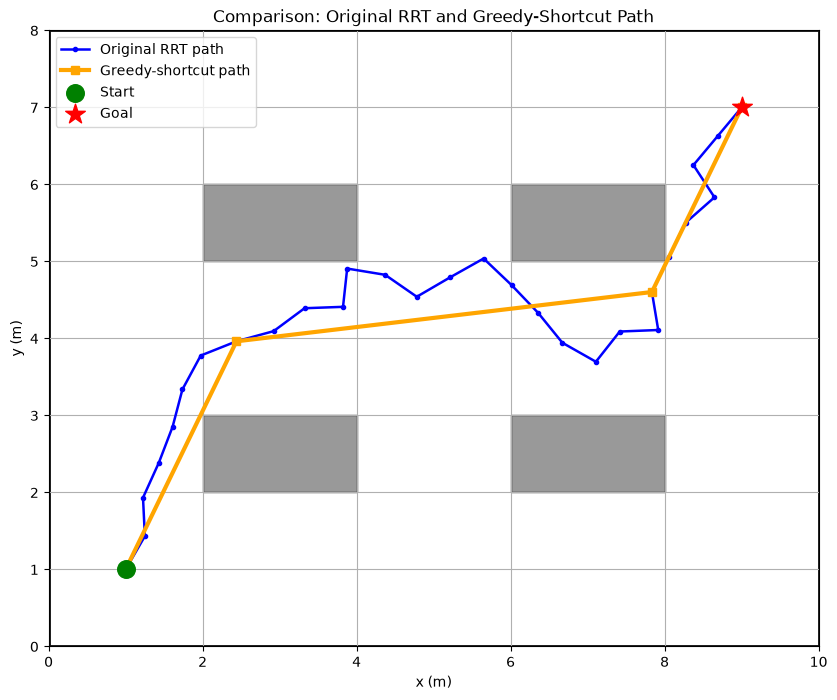

Path comparison
-----------------------------
Original RRT: 29 waypoints, 13.98 m
Greedy shortcut: 4 waypoints, 11.39 m


In [17]:
# Compare the original RRT path with its greedy-shortcut version

fig, ax = plt.subplots(figsize=(10, 8))

# Draw warehouse boundary
ax.add_patch(
    Rectangle(
        (0, 0),
        warehouse_width,
        warehouse_height,
        fill=False,
        linewidth=2
    )
)

# Draw obstacles
for x, y, width, height in obstacles:
    ax.add_patch(
        Rectangle(
            (x, y),
            width,
            height,
            facecolor="grey",
            edgecolor="black",
            alpha=0.8
        )
    )

# Plot original RRT path
original_positions = np.array(rrt_path)

ax.plot(
    original_positions[:, 0],
    original_positions[:, 1],
    color="blue",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="Original RRT path",
    zorder=3
)

# Plot greedy-shortcut path
simplified_positions = np.array(simplified_rrt_path)

ax.plot(
    simplified_positions[:, 0],
    simplified_positions[:, 1],
    color="orange",
    linewidth=3,
    marker="s",
    markersize=6,
    label="Greedy-shortcut path",
    zorder=4
)

# Highlight start and goal
ax.scatter(
    *start,
    color="green",
    marker="o",
    s=160,
    label="Start",
    zorder=5
)

ax.scatter(
    *goal,
    color="red",
    marker="*",
    s=220,
    label="Goal",
    zorder=5
)

ax.set_xlim(0, warehouse_width)
ax.set_ylim(0, warehouse_height)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Comparison: Original RRT and Greedy-Shortcut Path")
ax.legend()
ax.grid(True)

plt.show()

print("Path comparison")
print("-----------------------------")
print(f"Original RRT: {len(rrt_path)} waypoints, {path_length:.2f} m")
print(f"Greedy shortcut: {len(simplified_rrt_path)} waypoints, "
      f"{simplified_path_length:.2f} m")

## Representing the Original RRT Path as a Chromosome

Our original RRT planner generated a feasible route containing 29 waypoints.

Rather than optimizing the already simplified route, we will use the original RRT path as the starting solution for our genetic algorithm.

### 1. Chromosome Representation

The original path contains:

- One fixed starting position.
- 27 intermediate waypoints.
- One fixed goal position.

Each intermediate waypoint has two coordinates.

Therefore, the chromosome contains 54 real-valued variables:

$$
X=[x_1,y_1,x_2,y_2,\ldots,x_{27},y_{27}]
$$

The complete candidate path is reconstructed by adding the fixed start and goal positions:

$$
P(X)=\{q_{\text{start}},q_1,q_2,\ldots,q_{27},q_{\text{goal}}\}
$$

### 2. Initial Population

The original RRT chromosome will be retained as the reference candidate.

Additional chromosomes will be generated by introducing controlled variations in the intermediate waypoint coordinates.

This allows the genetic algorithm to explore alternative path configurations while preserving the original RRT solution as a baseline.

### 3. Genetic Operations

The algorithm will use:

- **Selection:** Prefer candidate paths with better fitness.
- **Crossover:** Combine waypoint information from two candidate paths.
- **Mutation:** Introduce small changes to selected waypoint coordinates.
- **Replacement:** Construct the next generation of candidate paths.

The ordering of waypoints will be preserved during these operations.

### 4. Fitness Evaluation

The primary optimization objective is to minimize total path length.

However, a shorter route is useful only if it remains collision-free.

Therefore, every candidate path must undergo collision checking.

A candidate containing an invalid connection will receive a substantial penalty.

### 5. Experimental Comparison

We will compare three results:

1. Original RRT path.
2. Greedy-shortcut path.
3. Best feasible genetic-algorithm path.

This comparison will help us investigate whether evolutionary optimization can improve the original RRT route and how its result compares with deterministic geometric shortcutting.

**Important:** A genetic algorithm does not guarantee a globally optimal path. Its performance depends on population initialization, fitness design, crossover, mutation and the number of generations.

In [18]:
# Encode the original RRT path as a genetic algorithm chromosome

# Keep the start and goal fixed
fixed_start = np.array(rrt_path[0], dtype=float)
fixed_goal = np.array(rrt_path[-1], dtype=float)

# Extract all intermediate waypoints
intermediate_waypoints = np.array(
    rrt_path[1:-1],
    dtype=float
)

# Convert the intermediate waypoint coordinates into a chromosome
initial_chromosome = intermediate_waypoints.flatten()

print("Initial GA chromosome")
print("-----------------------------")
print("Original RRT waypoints:", len(rrt_path))
print("Intermediate waypoints:", len(intermediate_waypoints))
print("Number of optimization variables:", len(initial_chromosome))
print("Fixed start:", fixed_start)
print("Fixed goal:", fixed_goal)

print("\nFirst five chromosome values:")
print(initial_chromosome[:5])

print("\nChromosome shape:", initial_chromosome.shape)

Initial GA chromosome
-----------------------------
Original RRT waypoints: 29
Intermediate waypoints: 27
Number of optimization variables: 54
Fixed start: [1. 1.]
Fixed goal: [9. 7.]

First five chromosome values:
[1.25002439 1.43299862 1.22586464 1.93241459 1.43210697]

Chromosome shape: (54,)


## Designing the Genetic Algorithm Fitness Function

The genetic algorithm needs a way to evaluate and compare candidate paths.

For our warehouse navigation problem, the primary objective is to minimize the total path length while ensuring that the route remains collision-free.

### 1. Path Length

For a candidate path containing consecutive waypoints, the total path length is:

$$
L(P)=\sum_{i=0}^{N-2}
\sqrt{(x_{i+1}-x_i)^2+(y_{i+1}-y_i)^2}
$$

A shorter path receives a better score.

### 2. Collision Penalty

Changing waypoint coordinates may cause a candidate path to intersect warehouse obstacles.

We will use the collision-checking functions developed earlier to examine every consecutive waypoint connection.

Let $C(P)$ represent the number of invalid path segments.

A path containing an invalid segment must receive a substantial penalty.

### 3. Fitness Objective

We will formulate the minimization objective as:

$$
J(P)=L(P)+\lambda C(P)
$$

where:

- $L(P)$ is the total path length.
- $C(P)$ is the number of collision-invalid segments.
- $\lambda$ is a large collision penalty.

For this experiment, we will use:

$$
\lambda=1000
$$

This penalty is deliberately much larger than any reasonable path-length difference within our warehouse.

Therefore, feasible paths will be strongly preferred over paths containing collisions.

### 4. How Will Candidates Be Compared?

Consider three candidate paths:

| Candidate | Path length | Invalid segments | Evaluation |
|---|---:|---:|---|
| A | 12 m | 0 | Feasible |
| B | 10 m | 1 | Penalized |
| C | 14 m | 0 | Feasible |

Candidate B is shorter, but it intersects an obstacle. Its penalty makes it less desirable than a feasible candidate.

Between candidates A and C, candidate A is preferred because it has the shorter feasible route.

### 5. What Will the Genetic Algorithm Optimize?

The algorithm will attempt to minimize $J(P)$ through successive generations.

Its operations will include:

1. Selection of better candidate paths.
2. Crossover between selected chromosomes.
3. Mutation of intermediate waypoint coordinates.
4. Evaluation of the resulting candidate paths.

The original RRT path will be retained as a feasible reference candidate.

### Engineering Consideration

A genetic algorithm is a stochastic optimization technique. It does not guarantee that every generation improves upon the previous one, nor does it guarantee a globally optimal solution.

We will track the best feasible path length across generations and compare the final result against the greedy-shortcut baseline of 11.39 m.

In [19]:
def reconstruct_candidate_path(chromosome):
    """
    Convert a chromosome into a complete path.

    The start and goal positions remain fixed.
    Only intermediate waypoint coordinates are optimized.
    """

    intermediate_points = np.asarray(chromosome, dtype=float).reshape(-1, 2)

    candidate_path = np.vstack([
        fixed_start,
        intermediate_points,
        fixed_goal
    ])

    return candidate_path


def evaluate_candidate_path(chromosome, collision_penalty=1000.0):
    """
    Evaluate a candidate path using path length and collision penalties.

    Returns:
        fitness_cost: Total objective value to minimize.
        path_length: Total geometric path length.
        invalid_segments: Number of collision-invalid segments.
        candidate_path: Reconstructed candidate path.
    """

    candidate_path = reconstruct_candidate_path(chromosome)

    # Calculate total path length
    segment_lengths = np.linalg.norm(
        np.diff(candidate_path, axis=0),
        axis=1
    )

    path_length = np.sum(segment_lengths)

    # Count collision-invalid segments
    invalid_segments = 0

    for i in range(len(candidate_path) - 1):
        if not is_path_collision_free(
            candidate_path[i],
            candidate_path[i + 1]
        ):
            invalid_segments += 1

    # Calculate objective value
    fitness_cost = (
        path_length + collision_penalty * invalid_segments
    )

    return (
        fitness_cost,
        path_length,
        invalid_segments,
        candidate_path
    )


# Evaluate the original RRT path as the reference candidate
reference_cost, reference_length, reference_collisions, reference_path = (
    evaluate_candidate_path(initial_chromosome)
)

print("Original RRT Candidate Evaluation")
print("---------------------------------")
print(f"Fitness cost: {reference_cost:.2f}")
print(f"Path length: {reference_length:.2f} m")
print(f"Invalid segments: {reference_collisions}")
print(f"Number of waypoints: {len(reference_path)}")

Original RRT Candidate Evaluation
---------------------------------
Fitness cost: 13.98
Path length: 13.98 m
Invalid segments: 0
Number of waypoints: 29


## Generating the Initial Population

The genetic algorithm does not optimize a single candidate path. It maintains a population of candidate solutions and improves them over successive generations.

Each chromosome represents one possible warehouse navigation path containing 27 intermediate waypoints.

### 1. Population Initialization

We will initialize the population using the original RRT chromosome as the reference.

The process is:

1. Retain the original RRT chromosome as the first population member.
2. Generate additional chromosomes by introducing small random variations to the intermediate waypoint coordinates.
3. Keep all waypoint coordinates within the warehouse boundaries.
4. Evaluate every candidate using the fitness function developed earlier.

The first chromosome is therefore a known feasible solution with a path length of 13.98 m.

### 2. Introducing Variation

For each intermediate waypoint, we introduce a small random displacement:

$$
x_i' = x_i + \epsilon_x
$$

$$
y_i' = y_i + \epsilon_y
$$

where the perturbations are sampled from a Gaussian distribution:

$$
\epsilon_x,\epsilon_y \sim \mathcal{N}(0,\sigma^2)
$$

Here, $\sigma$ controls the magnitude of the initial variation.

- A small value produces candidate paths close to the original RRT route.
- A large value creates greater variation but may introduce more collisions.

### 3. Population Parameters

For this experiment, we will begin with:

| Parameter | Initial value |
|---|---:|
| Population size | 40 |
| Number of intermediate waypoints | 27 |
| Chromosome length | 54 |
| Perturbation standard deviation | 0.25 m |

These are experimental parameters, not universal GA settings.

### 4. An Important Constraint

The original RRT chromosome must remain in the initial population.

This guarantees that the initial population contains at least one known feasible solution.

Other candidates may contain collisions. They will be evaluated using the collision penalty, and the genetic algorithm will attempt to improve them.

### What Will We Observe?

After generating the population, we will examine:

- Total number of candidate paths.
- Number of collision-free candidates.
- Best feasible path length in the initial population.

This establishes the baseline against which subsequent generations will be evaluated.

In [20]:
# Initialize the genetic algorithm population

population_size = 40
mutation_sigma_initial = 0.25

rng_ga = np.random.default_rng(42)

# The original RRT chromosome is retained as the first candidate
population = [initial_chromosome.copy()]

# Generate the remaining candidates through waypoint perturbations
for _ in range(population_size - 1):

    perturbation = rng_ga.normal(
        loc=0.0,
        scale=mutation_sigma_initial,
        size=initial_chromosome.shape
    )

    candidate = initial_chromosome + perturbation

    # Keep waypoint coordinates within warehouse boundaries
    candidate[0::2] = np.clip(
        candidate[0::2], 0, warehouse_width
    )

    candidate[1::2] = np.clip(
        candidate[1::2], 0, warehouse_height
    )

    population.append(candidate)


# Evaluate all candidates in the initial population
population_results = [
    evaluate_candidate_path(candidate)
    for candidate in population
]

population_costs = np.array([
    result[0] for result in population_results
])

population_lengths = np.array([
    result[1] for result in population_results
])

population_collisions = np.array([
    result[2] for result in population_results
])

# Identify collision-free candidates
feasible_indices = np.where(population_collisions == 0)[0]

print("Initial GA Population Evaluation")
print("--------------------------------")
print("Population size:", len(population))
print("Chromosome length:", len(population[0]))
print("Collision-free candidates:", len(feasible_indices))
print("Candidates with collisions:",
      population_size - len(feasible_indices))

if len(feasible_indices) > 0:
    best_initial_index = feasible_indices[
        np.argmin(population_lengths[feasible_indices])
    ]

    print("Best feasible candidate index:", best_initial_index)
    print(f"Best feasible path length: "
          f"{population_lengths[best_initial_index]:.2f} m")
else:
    print("No collision-free candidate found in the initial population.")

print(f"Original RRT path length: {reference_length:.2f} m")

Initial GA Population Evaluation
--------------------------------
Population size: 40
Chromosome length: 54
Collision-free candidates: 8
Candidates with collisions: 32
Best feasible candidate index: 0
Best feasible path length: 13.98 m
Original RRT path length: 13.98 m


## Evaluating the Initial Genetic Algorithm Population

The initial population contains 40 candidate paths generated from the original RRT solution.

### Observed Results

| Measure | Result |
|---|---:|
| Population size | 40 |
| Collision-free candidates | 8 |
| Candidates with collisions | 32 |
| Best feasible path length | 13.98 m |

### What Do These Results Tell Us?

Only 20% of the initial population contains collision-free paths.

This demonstrates an important characteristic of evolutionary path optimization: modifying waypoint coordinates does not necessarily preserve path feasibility.

Even relatively small changes can cause a connecting segment to intersect an obstacle.

### Why Is the Original RRT Candidate Important?

The original RRT chromosome remains the best feasible candidate in the initial population.

We must ensure that this solution is not lost during subsequent generations.

We will achieve this using **elitism**.

Elitism preserves the best candidate from one generation and transfers it directly into the next generation without modification.

### What Happens Next?

The genetic algorithm will use:

1. **Selection:** Prefer better candidate paths for reproduction.
2. **Crossover:** Combine portions of two parent chromosomes.
3. **Mutation:** Introduce variations in waypoint coordinates.
4. **Elitism:** Preserve the best candidate.
5. **Evaluation:** Measure the quality and feasibility of the new population.

### Engineering Observation

The initial population establishes the baseline for evolutionary improvement.

The important question is not whether the genetic algorithm generates different paths, but whether it progressively discovers shorter collision-free paths.

Our reference values are:

- Original RRT: 13.98 m
- Greedy shortcutting: 11.39 m

The genetic algorithm will be evaluated against both.

## Genetic Algorithm: Optimizing the RRT Path

We now have an initial population of 40 candidate paths. The genetic algorithm will evolve this population over successive generations to discover shorter collision-free routes.

We will combine the following operations into one optimization loop.

### 1. Tournament Selection

Randomly select a small group of candidates and choose the candidate with the lowest fitness cost.

Better candidate paths therefore have a higher probability of contributing to the next generation.

### 2. Crossover

Combine two parent chromosomes to produce new candidate paths.

Crossover will take place at waypoint boundaries so that the x and y coordinates of each waypoint remain together.

### 3. Mutation

Introduce small random changes to selected waypoint coordinates.

Mutation helps the population explore alternative routes rather than repeatedly reproducing similar solutions.

### 4. Elitism

Preserve the best feasible candidate from one generation to the next.

This prevents the genetic algorithm from losing its best-known solution because of crossover or mutation.

### 5. Fitness Evaluation

Evaluate each new candidate using the previously implemented objective:

$$
J(P)=L(P)+\lambda C(P)
$$

The algorithm minimizes this objective while strongly penalizing collision-invalid paths.

### Experimental Configuration

We will use:

| Parameter | Value |
|---|---:|
| Population size | 40 |
| Generations | 100 |
| Tournament size | 3 |
| Crossover probability | 0.8 |
| Mutation probability | 0.15 |
| Mutation standard deviation | 0.12 m |
| Elitism | 1 candidate |

These parameters provide a starting configuration for experimentation. They are not guaranteed to be optimal.

### What Will We Evaluate?

After optimization, we will compare:

1. Original RRT path.
2. Greedy-shortcut path.
3. Best feasible genetic-algorithm path.

We will also plot the best feasible path length across generations to observe the evolutionary search process.

**Important:** The genetic algorithm is stochastic. It does not guarantee a globally optimal path or guarantee improvement over greedy shortcutting. The actual result will determine which approach performs better in this experiment.

GENETIC ALGORITHM RESULTS
Generations: 100
Population size: 40
Best feasible path length: 11.34 m
Invalid path segments: 0
Number of waypoints: 29

PATH COMPARISON
Original RRT:       13.98 m
Greedy shortcut:    11.39 m
Genetic algorithm:  11.34 m

Improvement over original RRT: 18.89%
Improvement over greedy shortcut: 0.50%


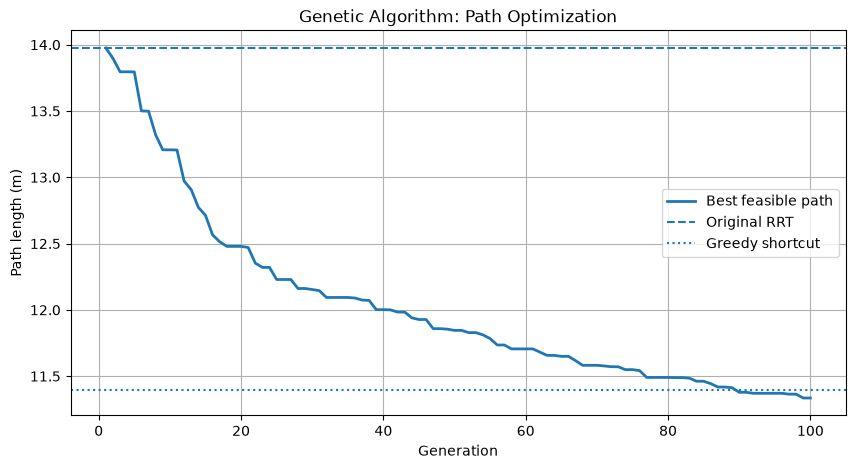

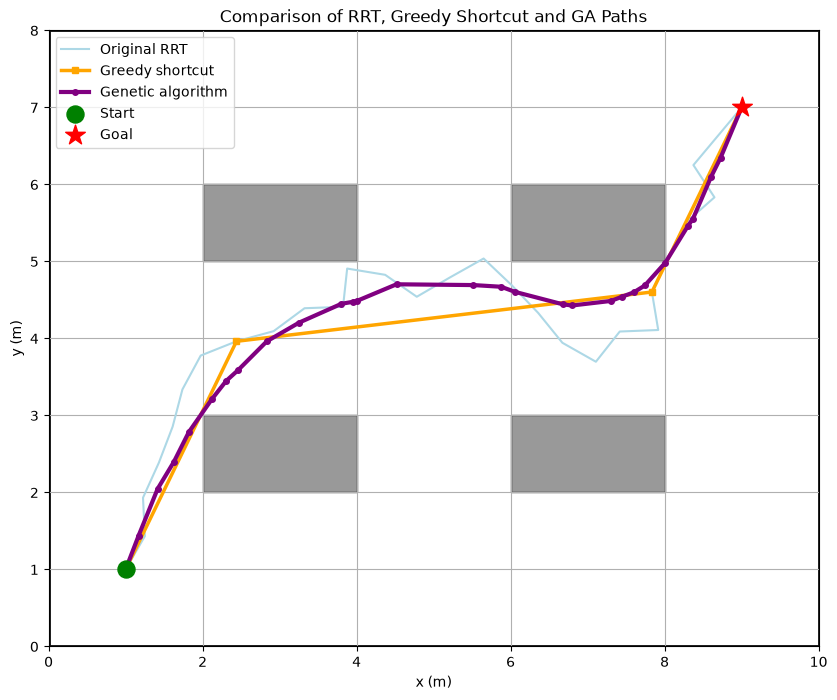

In [21]:
# ============================================================
# GENETIC ALGORITHM FOR RRT PATH OPTIMIZATION
# ============================================================

# Reproducible GA execution
ga_rng = np.random.default_rng(123)

# ------------------------------------------------------------
# 1. GA PARAMETERS
# ------------------------------------------------------------

ga_population_size = 40
ga_generations = 100
tournament_size = 3
crossover_probability = 0.8
mutation_probability = 0.15
mutation_sigma = 0.12
elite_count = 1

# Start with the population generated in Cell 43
ga_population = [candidate.copy() for candidate in population]

# Preserve the best known feasible solution
best_feasible_chromosome = initial_chromosome.copy()
best_feasible_cost, best_feasible_length, _, _ = (
    evaluate_candidate_path(best_feasible_chromosome)
)

# Track optimization progress
best_length_history = []
mean_feasible_length_history = []
feasible_count_history = []

# ------------------------------------------------------------
# 2. TOURNAMENT SELECTION
# ------------------------------------------------------------

def tournament_selection(population, costs, tournament_size, rng):
    selected_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    winner_index = selected_indices[
        np.argmin(costs[selected_indices])
    ]

    return population[winner_index].copy()


# ------------------------------------------------------------
# 3. CROSSOVER
# ------------------------------------------------------------

def crossover(parent1, parent2, rng):
    """
    One-point crossover at a waypoint boundary.
    Each x-y coordinate pair remains together.
    """

    if rng.random() > crossover_probability:
        return parent1.copy(), parent2.copy()

    number_of_waypoints = len(parent1) // 2

    crossover_point = rng.integers(
        1, number_of_waypoints
    )

    coordinate_index = 2 * crossover_point

    child1 = np.concatenate([
        parent1[:coordinate_index],
        parent2[coordinate_index:]
    ])

    child2 = np.concatenate([
        parent2[:coordinate_index],
        parent1[coordinate_index:]
    ])

    return child1, child2


# ------------------------------------------------------------
# 4. MUTATION
# ------------------------------------------------------------

def mutate(chromosome, rng):
    """
    Mutate intermediate waypoint coordinates.
    Start and goal are not part of the chromosome.
    """

    mutated = chromosome.copy()

    number_of_waypoints = len(mutated) // 2

    for waypoint_index in range(number_of_waypoints):

        if rng.random() < mutation_probability:

            coordinate_index = 2 * waypoint_index

            mutated[coordinate_index] += rng.normal(
                0, mutation_sigma
            )

            mutated[coordinate_index + 1] += rng.normal(
                0, mutation_sigma
            )

    # Enforce warehouse boundaries
    mutated[0::2] = np.clip(
        mutated[0::2], 0, warehouse_width
    )

    mutated[1::2] = np.clip(
        mutated[1::2], 0, warehouse_height
    )

    return mutated


# ------------------------------------------------------------
# 5. EVOLUTIONARY OPTIMIZATION
# ------------------------------------------------------------

for generation in range(ga_generations):

    # Evaluate current population
    results = [
        evaluate_candidate_path(candidate)
        for candidate in ga_population
    ]

    costs = np.array([result[0] for result in results])
    lengths = np.array([result[1] for result in results])
    collisions = np.array([result[2] for result in results])

    feasible_indices = np.where(collisions == 0)[0]

    # Update best feasible solution
    if len(feasible_indices) > 0:

        generation_best_index = feasible_indices[
            np.argmin(lengths[feasible_indices])
        ]

        generation_best_length = lengths[generation_best_index]

        if generation_best_length < best_feasible_length:

            best_feasible_chromosome = (
                ga_population[generation_best_index].copy()
            )

            best_feasible_length = generation_best_length

            best_feasible_cost = costs[generation_best_index]

    # Record generation statistics
    best_length_history.append(best_feasible_length)

    if len(feasible_indices) > 0:
        mean_feasible_length_history.append(
            np.mean(lengths[feasible_indices])
        )
    else:
        mean_feasible_length_history.append(np.nan)

    feasible_count_history.append(len(feasible_indices))

    # Rank population by objective cost
    ranked_indices = np.argsort(costs)

    # Elitism: preserve the best candidate
    next_population = [
        ga_population[ranked_indices[i]].copy()
        for i in range(elite_count)
    ]

    # Generate the remaining population
    while len(next_population) < ga_population_size:

        parent1 = tournament_selection(
            ga_population, costs, tournament_size, ga_rng
        )

        parent2 = tournament_selection(
            ga_population, costs, tournament_size, ga_rng
        )

        child1, child2 = crossover(
            parent1, parent2, ga_rng
        )

        child1 = mutate(child1, ga_rng)
        child2 = mutate(child2, ga_rng)

        next_population.append(child1)

        if len(next_population) < ga_population_size:
            next_population.append(child2)

    ga_population = next_population

    # Reduce mutation magnitude gradually
    mutation_sigma *= 0.99


# ------------------------------------------------------------
# 6. FINAL EVALUATION
# ------------------------------------------------------------

ga_best_path = reconstruct_candidate_path(
    best_feasible_chromosome
)

ga_final_cost, ga_final_length, ga_final_collisions, _ = (
    evaluate_candidate_path(best_feasible_chromosome)
)

print("GENETIC ALGORITHM RESULTS")
print("====================================")
print("Generations:", ga_generations)
print("Population size:", ga_population_size)
print("Best feasible path length:",
      f"{ga_final_length:.2f} m")
print("Invalid path segments:", ga_final_collisions)
print("Number of waypoints:", len(ga_best_path))

print("\nPATH COMPARISON")
print("====================================")
print(f"Original RRT:       {path_length:.2f} m")
print(f"Greedy shortcut:    {simplified_path_length:.2f} m")
print(f"Genetic algorithm:  {ga_final_length:.2f} m")

print("\nImprovement over original RRT:",
      f"{(path_length - ga_final_length) / path_length * 100:.2f}%")

print("Improvement over greedy shortcut:",
      f"{(simplified_path_length - ga_final_length) / simplified_path_length * 100:.2f}%")


# ------------------------------------------------------------
# 7. PLOT EVOLUTIONARY CONVERGENCE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(1, ga_generations + 1),
    best_length_history,
    linewidth=2,
    label="Best feasible path"
)

ax.axhline(
    path_length,
    linestyle="--",
    label="Original RRT"
)

ax.axhline(
    simplified_path_length,
    linestyle=":",
    label="Greedy shortcut"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Path length (m)")
ax.set_title("Genetic Algorithm: Path Optimization")
ax.legend()
ax.grid(True)

plt.show()


# ------------------------------------------------------------
# 8. VISUALIZE FINAL GA PATH
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

ax.add_patch(
    Rectangle(
        (0, 0),
        warehouse_width,
        warehouse_height,
        fill=False,
        linewidth=2
    )
)

for x, y, width, height in obstacles:
    ax.add_patch(
        Rectangle(
            (x, y),
            width,
            height,
            facecolor="grey",
            edgecolor="black",
            alpha=0.8
        )
    )

# Original RRT path
ax.plot(
    original_positions[:, 0],
    original_positions[:, 1],
    color="lightblue",
    linewidth=1.5,
    label="Original RRT"
)

# Greedy shortcut path
ax.plot(
    simplified_positions[:, 0],
    simplified_positions[:, 1],
    color="orange",
    linewidth=2.5,
    marker="s",
    markersize=5,
    label="Greedy shortcut"
)

# Genetic algorithm path
ax.plot(
    ga_best_path[:, 0],
    ga_best_path[:, 1],
    color="purple",
    linewidth=3,
    marker="o",
    markersize=4,
    label="Genetic algorithm"
)

ax.scatter(
    *start,
    color="green",
    marker="o",
    s=150,
    label="Start",
    zorder=5
)

ax.scatter(
    *goal,
    color="red",
    marker="*",
    s=220,
    label="Goal",
    zorder=5
)

ax.set_xlim(0, warehouse_width)
ax.set_ylim(0, warehouse_height)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Comparison of RRT, Greedy Shortcut and GA Paths")
ax.legend()
ax.grid(True)

plt.show()

## Interpreting the Genetic Algorithm Results

The Genetic Algorithm (GA) was executed for 100 generations with a population size of 40. The best feasible solution produced a collision-free path of **11.34 m**.

### Comparison of Path Planning Approaches

| Planning approach | Path length |
|---|---:|
| Original RRT | 13.98 m |
| RRT with greedy shortcutting | 11.39 m |
| RRT with Genetic Algorithm optimization | **11.34 m** |

### What Do These Results Tell Us?

**1. RRT provides a feasible path, but not necessarily an efficient one.**

The original RRT generated a collision-free path of 13.98 m. However, its exploration-based construction can introduce unnecessary turns and intermediate waypoints.

**2. Greedy shortcutting provides a substantial improvement.**

Greedy shortcutting reduced the path length from 13.98 m to 11.39 m, an improvement of approximately 18.51%. This demonstrates that simple geometric post-processing can significantly improve a sampling-based planner's output.

**3. Genetic Algorithm provides a marginal additional improvement.**

The GA reduced the path length further to 11.34 m:
- Improvement over original RRT: **18.89%**
- Improvement over greedy shortcutting: **0.50%**

The GA found a slightly shorter collision-free solution by optimizing the coordinates of the intermediate waypoints.

### Engineering Interpretation

An important observation is that a more sophisticated optimization algorithm does not automatically produce a substantially better result.

In this experiment, greedy shortcutting achieved nearly the same path quality as the Genetic Algorithm, with a simpler optimization procedure. The GA improved the path by only 0.05 m over greedy shortcutting.

Therefore, algorithm selection should consider not only path quality but also computational cost, implementation complexity, reliability, and the requirements of the application.

**Note:** The GA optimized the intermediate waypoint coordinates of the original RRT path while retaining the start and goal positions. It does not guarantee a globally optimal path.

### Key Takeaway

RRT explores the configuration space to discover a feasible path. Greedy shortcutting and Genetic Algorithms can then improve the quality of that path.

The choice of optimization technique should be justified by the improvement it provides relative to its computational and implementation costs.

---

## Transition to Lab 7

So far, we have explicitly constructed a path using sampling-based planning and improved it using evolutionary optimization.

But what if the robot could learn how to navigate through its environment by interacting with it, receiving feedback, and improving its decisions through experience?

This leads us to **Deep Reinforcement Learning for Path Planning**, the focus of Lab 7.

## Lab 7: Deep Reinforcement Learning for Path Planning

### From Computing Paths to Learning Navigation Behaviour

In Lab 6, we used RRT to explore the warehouse environment and identify a collision-free path. We then applied greedy shortcutting and Genetic Algorithm optimization to improve the path.

These approaches explicitly construct a path using geometric planning and optimization techniques.

Now consider a different approach.

Instead of calculating a complete path before the robot moves, can we train the robot to learn which action it should take in a given situation?

For example, when the warehouse robot approaches an obstacle, it must learn whether to move forward, turn left, or turn right. It receives feedback from the environment based on its decisions and gradually improves its navigation behaviour.

This is the central idea of **Reinforcement Learning (RL)**.

### What Is Deep Reinforcement Learning?

Reinforcement Learning is a learning paradigm in which an agent interacts with an environment, takes actions, receives rewards or penalties, and learns a strategy to maximize its cumulative reward.

Deep Reinforcement Learning combines reinforcement learning with deep neural networks. Instead of storing or explicitly calculating values for every possible state, a neural network learns to approximate the value of taking an action in a particular state.

In our warehouse robot scenario:

- **Agent:** Autonomous mobile robot.
- **Environment:** Warehouse with obstacles.
- **State:** Robot's current position and information about the goal.
- **Action:** A discrete movement command.
- **Reward:** Feedback based on progress, collisions, and reaching the goal.
- **Policy:** The learned decision-making behaviour of the robot.

### The Learning Process

The robot repeatedly interacts with the environment:

1. Observe the current state.
2. Select an action.
3. Execute the action.
4. Receive a reward.
5. Observe the next state.
6. Update the learning model.
7. Repeat until the episode terminates.

Through repeated interactions, the agent learns a navigation policy that maps observed states to actions.

### Objective of This Laboratory

In this experiment, we will implement a Deep Q-Network (DQN) to learn navigation behaviour in the warehouse environment introduced in Lab 6.

We will train the agent, evaluate its learned behaviour, visualize the resulting route, and compare its performance with the classical and evolutionary approaches.

**Central question:** Can a robot learn a useful navigation strategy through experience rather than relying entirely on an explicitly computed path?

## Formulating Warehouse Navigation as a Deep Reinforcement Learning Problem

To apply Deep Reinforcement Learning, we must first represent the robot's navigation task in a form that an agent can learn from.

We will formulate the warehouse navigation problem as a Markov Decision Process (MDP).

An MDP is defined by five components:

$$
MDP = (S, A, P, R, \gamma)
$$

where:

- $S$: Set of possible states.
- $A$: Set of available actions.
- $P$: State transition dynamics.
- $R$: Reward function.
- $\gamma$: Discount factor.

### 1. State Representation

The agent must know enough about its current situation to make a navigation decision.

For this experiment, the state will contain:

- Robot's current x-coordinate.
- Robot's current y-coordinate.
- Relative x-distance to the goal.
- Relative y-distance to the goal.

The state vector is:

$$
s_t = [x_t,\ y_t,\ \Delta x_t,\ \Delta y_t]
$$

where:

$$
\Delta x_t = x_{goal} - x_t
$$

$$
\Delta y_t = y_{goal} - y_t
$$

The coordinates and relative distances will be normalized before being supplied to the neural network.

**Engineering interpretation:** The agent knows its current position and the direction and distance of the goal. The warehouse obstacle layout remains fixed and is known to the environment during training.

This is a simplified state representation for a fixed warehouse map. It is not a general-purpose perception system.

### 2. Action Space

The robot will use four discrete movement actions:

| Action | Movement |
|---|---|
| 0 | Move right |
| 1 | Move left |
| 2 | Move up |
| 3 | Move down |

Each action moves the robot by a fixed distance.

This discrete action space simplifies the learning problem and allows us to use a Deep Q-Network.

### 3. State Transitions

When the agent selects an action, the environment updates the robot's position.

The proposed movement is checked against the warehouse boundaries and obstacles.

- If the movement is valid, the robot moves to the new position.
- If the movement results in a collision, the robot remains at its previous position and receives a penalty.
- If the robot reaches the goal, the episode terminates successfully.
- An episode also terminates when the maximum number of steps is reached.

The environment therefore acts as the simulator through which the agent learns.

### 4. Reward Design

The reward function guides the agent towards desirable navigation behaviour.

We will use the following reward structure:

| Event | Reward |
|---|---:|
| Reaching the goal | +100 |
| Collision or invalid movement | -10 |
| Valid movement | -1 |
| Progress towards the goal | Additional positive reward |

The progress reward is based on the reduction in Euclidean distance to the goal:

$$
d_t = \sqrt{(x_{goal}-x_t)^2+(y_{goal}-y_t)^2}
$$

$$
r_{progress} = k(d_t-d_{t+1})
$$

where $k$ controls the strength of the progress reward.

If the robot moves closer to the goal, the progress reward is positive. If it moves away, the reward is negative.

**Why is reward design important?**

The agent does not inherently understand what a good path is. It learns from the reward signal. Poorly designed rewards can produce undesirable behaviour, even when the neural network and training algorithm are implemented correctly.

### 5. Deep Q-Network (DQN)

A conventional Q-learning algorithm estimates the value of taking an action in a particular state.

The action-value function is:

$$
Q(s,a)
$$

It represents the expected cumulative future reward when action $a$ is selected in state $s$, followed by an appropriate policy.

In a Deep Q-Network, a neural network approximates this function:

$$
Q(s,a;\theta)
$$

where $\theta$ represents the neural network parameters.

The network receives the state as input and produces one Q-value for each available action.

The agent selects the action with the highest predicted Q-value during exploitation:

$$
a_t = \arg\max_a Q(s_t,a;\theta)
$$

### 6. How Does the Agent Learn?

DQN uses three important mechanisms.

**A. Epsilon-Greedy Action Selection**

The agent must balance exploration and exploitation.

- Exploration: Select a random action to discover alternative behaviours.
- Exploitation: Select the action with the highest predicted Q-value.

The probability of exploration is controlled by epsilon ($\epsilon$).

Initially, epsilon is high so the agent explores more. As training progresses, epsilon is reduced so that the agent increasingly uses what it has learned.

**B. Experience Replay**

Every interaction is stored as a transition:

$$
(s_t,a_t,r_t,s_{t+1},done)
$$

These experiences are stored in a replay buffer.

Instead of learning only from the most recent transition, the agent randomly samples a batch of previous experiences to train the network.

This reduces dependence on the order of consecutive observations and improves training stability.

**C. Target Network**

DQN maintains a second neural network called the target network.

The target network is periodically updated using the parameters of the main Q-network. It provides a more stable target during training.

The target Q-value is:

$$
y_t = r_t + \gamma(1-done)\max_{a'}Q_{target}(s_{t+1},a')
$$

where $done$ indicates whether the episode has terminated.

The network is trained by minimizing the difference between its predicted Q-value and the target Q-value:

$$
L(\theta) = \mathbb{E}\left[(y_t-Q(s_t,a_t;\theta))^2\right]
$$

### 7. Overall Training Process

The complete DQN training process is:

1. Initialize the warehouse environment.
2. Initialize the main Q-network and target network.
3. Initialize the experience replay buffer.
4. Reset the environment and obtain the initial state.
5. Select an action using epsilon-greedy selection.
6. Execute the action and observe the reward and next state.
7. Store the transition in the replay buffer.
8. Sample a random mini-batch of transitions.
9. Calculate target Q-values and update the main network.
10. Periodically update the target network.
11. Reduce epsilon gradually.
12. Repeat across multiple training episodes.

### 8. What Will We Evaluate?

After training, we will evaluate the learned policy without random exploration.

We will examine:

- Whether the agent reaches the goal.
- Whether it avoids obstacles.
- The number of steps required.
- The resulting path length.
- The evolution of cumulative rewards during training.

We will then compare the learned route with the RRT, greedy shortcutting, and GA results from Lab 6.

**Important limitation:** A successful result in this fixed warehouse environment does not establish that the agent can navigate unfamiliar warehouse layouts. Generalization would require additional training and evaluation across different maps, obstacle configurations, and start-goal combinations.

In [23]:
# ============================================================
# LAB 7: DEEP REINFORCEMENT LEARNING
# CELL 50A: WAREHOUSE NAVIGATION ENVIRONMENT
# ============================================================

import numpy as np

class WarehouseEnvironment:

    def __init__(self):

        # Reuse the warehouse configuration from Lab 6
        self.start = np.array(start, dtype=float)
        self.goal = np.array(goal, dtype=float)

        self.step_size = 0.5
        self.max_steps = 100
        self.goal_threshold = 0.35

        # Four discrete navigation actions
        self.actions = {
            0: np.array([self.step_size, 0.0]),    # Right
            1: np.array([-self.step_size, 0.0]),   # Left
            2: np.array([0.0, self.step_size]),    # Up
            3: np.array([0.0, -self.step_size])    # Down
        }

        self.reset()

    # --------------------------------------------------------
    # Reset the environment at the beginning of an episode
    # --------------------------------------------------------

    def reset(self):

        self.position = self.start.copy()
        self.steps = 0
        self.path = [self.position.copy()]

        return self.get_state()

    # --------------------------------------------------------
    # Construct the state representation
    # --------------------------------------------------------

    def get_state(self):

        relative_goal = self.goal - self.position

        state = np.array([
            self.position[0] / warehouse_width,
            self.position[1] / warehouse_height,
            relative_goal[0] / warehouse_width,
            relative_goal[1] / warehouse_height
        ], dtype=np.float32)

        return state

    # --------------------------------------------------------
    # Execute an action and return the resulting transition
    # --------------------------------------------------------

    def step(self, action):

        self.steps += 1

        old_position = self.position.copy()

        old_distance = np.linalg.norm(
            self.goal - old_position
        )

        proposed_position = (
            old_position + self.actions[action]
        )

        # Validate the proposed movement using Lab 6
        valid_move = is_path_collision_free(
            old_position,
            proposed_position
        )

        collision = not valid_move

        if valid_move:
            self.position = proposed_position

        new_distance = np.linalg.norm(
            self.goal - self.position
        )

        # ----------------------------------------------------
        # Reward calculation
        # ----------------------------------------------------

        # Reward or penalty based on progress towards the goal
        progress_reward = 2.0 * (
            old_distance - new_distance
        )

        # Small penalty for every movement
        reward = -1.0 + progress_reward

        # Penalty for collision or invalid movement
        if collision:
            reward = -10.0

        # Check whether the robot has reached the goal
        reached_goal = (
            new_distance <= self.goal_threshold
        )

        if reached_goal:
            reward += 100.0

        # Episode termination conditions
        done = (
            reached_goal or
            self.steps >= self.max_steps
        )

        self.path.append(self.position.copy())

        return (
            self.get_state(),
            reward,
            done,
            {
                "reached_goal": reached_goal,
                "collision": collision
            }
        )


# ------------------------------------------------------------
# Create and test the warehouse environment
# ------------------------------------------------------------

environment = WarehouseEnvironment()

initial_state = environment.reset()

print("Warehouse environment initialized")
print("-----------------------------------")
print("Start position:", environment.position)
print("Goal position:", environment.goal)
print("Initial state:", initial_state)
print("Number of actions:", len(environment.actions))
print("Maximum steps per episode:", environment.max_steps)

# Test one action: Move right
next_state, reward, done, info = environment.step(0)

print("\nSingle-action test")
print("------------------")
print("Action: Move right")
print("New position:", environment.position)
print("Next state:", next_state)
print("Reward:", reward)
print("Episode terminated:", done)
print("Additional information:", info)

# Reset after testing
environment.reset()

Warehouse environment initialized
-----------------------------------
Start position: [1. 1.]
Goal position: [9. 7.]
Initial state: [0.1   0.125 0.8   0.75 ]
Number of actions: 4
Maximum steps per episode: 100

Single-action test
------------------
Action: Move right
New position: [1.5 1. ]
Next state: [0.15  0.125 0.75  0.75 ]
Reward: -0.2093727122985456
Episode terminated: False
Additional information: {'reached_goal': np.False_, 'collision': False}


array([0.1  , 0.125, 0.8  , 0.75 ], dtype=float32)

In [24]:
# ============================================================
# LAB 7: DEEP REINFORCEMENT LEARNING
# CELL 50B: DQN ARCHITECTURE AND LEARNING COMPONENTS
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Training device:", device)


# ------------------------------------------------------------
# 1. DEEP Q-NETWORK
# ------------------------------------------------------------

class QNetwork(nn.Module):

    def __init__(self, state_size, action_size):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, action_size)
        )

    def forward(self, state):
        return self.network(state)


# ------------------------------------------------------------
# 2. EXPERIENCE REPLAY BUFFER
# ------------------------------------------------------------

class ReplayBuffer:

    def __init__(self, capacity=20000):

        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):

        self.buffer.append(
            (state, action, reward, next_state, done)
        )

    def sample(self, batch_size):

        batch = random.sample(
            self.buffer, batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)


# ------------------------------------------------------------
# 3. INITIALIZE DQN AGENT
# ------------------------------------------------------------

state_size = 4
action_size = 4

q_network = QNetwork(
    state_size, action_size
).to(device)

target_network = QNetwork(
    state_size, action_size
).to(device)

# Initially synchronize both networks
target_network.load_state_dict(
    q_network.state_dict()
)

target_network.eval()

optimizer = optim.Adam(
    q_network.parameters(),
    lr=0.001
)

loss_function = nn.MSELoss()

replay_buffer = ReplayBuffer(
    capacity=20000
)

# DQN hyperparameters
gamma = 0.99
batch_size = 64

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

target_update_frequency = 200

gradient_updates = 0


# ------------------------------------------------------------
# 4. EPSILON-GREEDY ACTION SELECTION
# ------------------------------------------------------------

def select_action(state, epsilon):

    # Exploration: select a random action
    if random.random() < epsilon:
        return random.randrange(action_size)

    # Exploitation: select the action with the highest Q-value
    state_tensor = torch.tensor(
        state,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        q_values = q_network(state_tensor)

    return int(
        torch.argmax(q_values).item()
    )


# ------------------------------------------------------------
# 5. DQN LEARNING UPDATE
# ------------------------------------------------------------

def train_dqn():

    global gradient_updates

    # Wait until sufficient experiences are available
    if len(replay_buffer) < batch_size:
        return None

    # Sample a random mini-batch
    (
        states,
        actions,
        rewards,
        next_states,
        dones
    ) = replay_buffer.sample(batch_size)

    states_tensor = torch.tensor(
        states
    ).to(device)

    actions_tensor = torch.tensor(
        actions
    ).to(device)

    rewards_tensor = torch.tensor(
        rewards
    ).to(device)

    next_states_tensor = torch.tensor(
        next_states
    ).to(device)

    dones_tensor = torch.tensor(
        dones
    ).to(device)

    # Predicted Q-values for the selected actions
    current_q_values = q_network(
        states_tensor
    ).gather(
        1,
        actions_tensor.unsqueeze(1)
    ).squeeze(1)

    # Calculate target Q-values
    with torch.no_grad():

        next_q_values = target_network(
            next_states_tensor
        ).max(dim=1)[0]

        target_q_values = (
            rewards_tensor
            + gamma
            * (1.0 - dones_tensor)
            * next_q_values
        )

    # Calculate loss
    loss = loss_function(
        current_q_values,
        target_q_values
    )

    # Backpropagation and parameter update
    optimizer.zero_grad()

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        q_network.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    gradient_updates += 1

    # Periodically update the target network
    if gradient_updates % target_update_frequency == 0:

        target_network.load_state_dict(
            q_network.state_dict()
        )

    return loss.item()


# ------------------------------------------------------------
# 6. VERIFY NETWORK AND AGENT INITIALIZATION
# ------------------------------------------------------------

test_state = environment.reset()

test_tensor = torch.tensor(
    test_state,
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    predicted_q_values = q_network(test_tensor)

print("\nDQN agent initialized successfully")
print("------------------------------------")
print("State dimension:", state_size)
print("Number of actions:", action_size)
print("Q-network output:", predicted_q_values.cpu().numpy())
print("Replay buffer capacity:", replay_buffer.buffer.maxlen)
print("Initial epsilon:", epsilon)
print("Discount factor:", gamma)
print("Batch size:", batch_size)
print("Target network synchronized:", True)

PyTorch version: 2.14.1
Training device: cpu

DQN agent initialized successfully
------------------------------------
State dimension: 4
Number of actions: 4
Q-network output: [[ 0.05296576 -0.01120952  0.08853137 -0.01495827]]
Replay buffer capacity: 20000
Initial epsilon: 1.0
Discount factor: 0.99
Batch size: 64
Target network synchronized: True


Starting DQN training...

Episode  200 | Success rate:   0.5% | Mean reward: -144.03 | Epsilon: 0.367
Episode  400 | Success rate:   0.0% | Mean reward: -118.56 | Epsilon: 0.135
Episode  600 | Success rate:  20.5% | Mean reward:  -68.95 | Epsilon: 0.050
Episode  800 | Success rate:  95.0% | Mean reward:   56.03 | Epsilon: 0.050
Episode 1000 | Success rate:  98.5% | Mean reward:   80.67 | Epsilon: 0.050
Episode 1200 | Success rate: 100.0% | Mean reward:   83.92 | Epsilon: 0.050
Episode 1400 | Success rate:  99.5% | Mean reward:   84.94 | Epsilon: 0.050
Episode 1600 | Success rate: 100.0% | Mean reward:   88.91 | Epsilon: 0.050
Episode 1800 | Success rate:  99.5% | Mean reward:   84.93 | Epsilon: 0.050
Episode 2000 | Success rate: 100.0% | Mean reward:   88.19 | Epsilon: 0.050


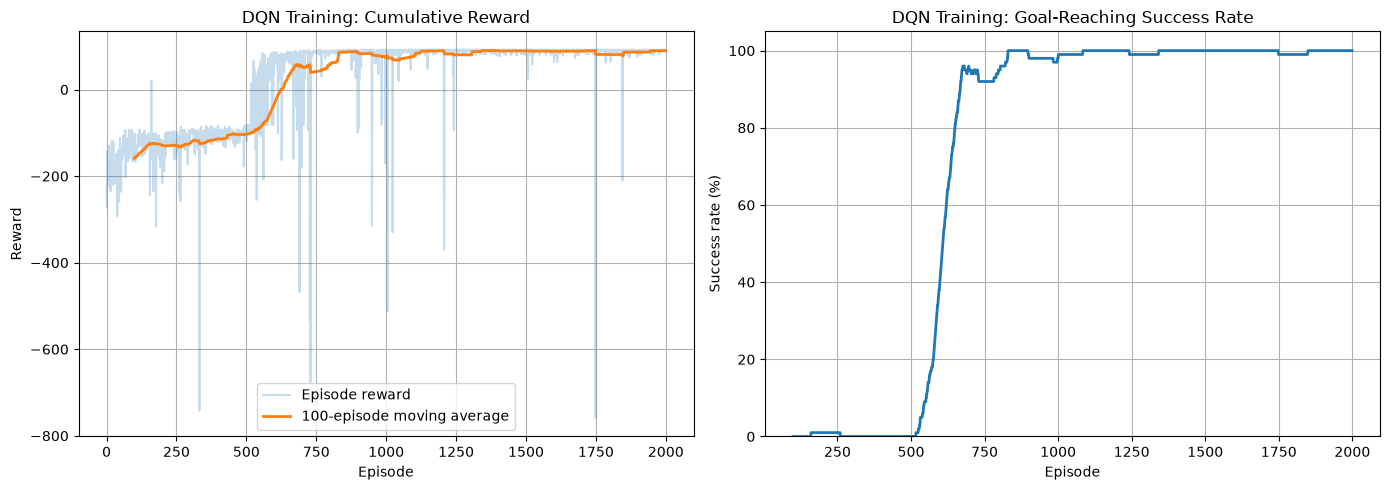


TRAINING SUMMARY
Training episodes: 2000
Final epsilon: 0.05
Total stored experiences: 20000
Total gradient updates: 104305
Final 100-episode success rate: 100.0 %
Final 100-episode mean reward: 89.84


In [25]:
# ============================================================
# LAB 7: DEEP REINFORCEMENT LEARNING
# CELL 50C: TRAINING THE DQN AGENT
# ============================================================

# Training configuration
training_episodes = 2000

training_rewards = []
training_success = []
training_steps = []

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

print("Starting DQN training...\n")

for episode in range(training_episodes):

    state = environment.reset()

    total_reward = 0.0
    episode_steps = 0
    reached_goal = False

    for step in range(environment.max_steps):

        # Select action using epsilon-greedy strategy
        action = select_action(state, epsilon)

        # Execute action in the warehouse environment
        next_state, reward, done, info = environment.step(action)

        # Store the transition
        replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        # Update the DQN using replay experiences
        train_dqn()

        state = next_state
        total_reward += reward
        episode_steps += 1

        if done:
            reached_goal = info["reached_goal"]
            break

    # Reduce exploration after each episode
    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    # Record episode performance
    training_rewards.append(total_reward)
    training_success.append(int(reached_goal))
    training_steps.append(episode_steps)

    # Display progress every 200 episodes
    if (episode + 1) % 200 == 0:

        recent_success = np.mean(
            training_success[-200:]
        ) * 100

        recent_reward = np.mean(
            training_rewards[-200:]
        )

        print(
            f"Episode {episode + 1:4d} | "
            f"Success rate: {recent_success:5.1f}% | "
            f"Mean reward: {recent_reward:7.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )


# ------------------------------------------------------------
# PLOT TRAINING PERFORMANCE
# ------------------------------------------------------------

window_size = 100

moving_average_rewards = np.convolve(
    training_rewards,
    np.ones(window_size) / window_size,
    mode="valid"
)

moving_average_success = np.convolve(
    training_success,
    np.ones(window_size) / window_size,
    mode="valid"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cumulative reward
axes[0].plot(
    training_rewards,
    alpha=0.25,
    label="Episode reward"
)

axes[0].plot(
    np.arange(window_size - 1, training_episodes),
    moving_average_rewards,
    linewidth=2,
    label="100-episode moving average"
)

axes[0].set_title("DQN Training: Cumulative Reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Reward")
axes[0].legend()
axes[0].grid(True)

# Goal-reaching success rate
axes[1].plot(
    np.arange(window_size - 1, training_episodes),
    moving_average_success * 100,
    linewidth=2
)

axes[1].set_title("DQN Training: Goal-Reaching Success Rate")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Success rate (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# TRAINING SUMMARY
# ------------------------------------------------------------

print("\nTRAINING SUMMARY")
print("=" * 45)

print("Training episodes:", training_episodes)
print("Final epsilon:", round(epsilon, 3))
print("Total stored experiences:", len(replay_buffer))
print("Total gradient updates:", gradient_updates)

print(
    "Final 100-episode success rate:",
    round(np.mean(training_success[-100:]) * 100, 2),
    "%"
)

print(
    "Final 100-episode mean reward:",
    round(np.mean(training_rewards[-100:]), 2)
)

DQN EVALUATION RESULTS
Goal reached: True
Number of steps: 28
Path length: 14.0 m
Collisions: 0
Total evaluation reward: 92.0
Path collision-free: True

PATH PLANNING COMPARISON
Original RRT:       13.98 m
Greedy shortcut:    11.39 m
Genetic Algorithm:  11.34 m
DQN learned route:  14.00 m


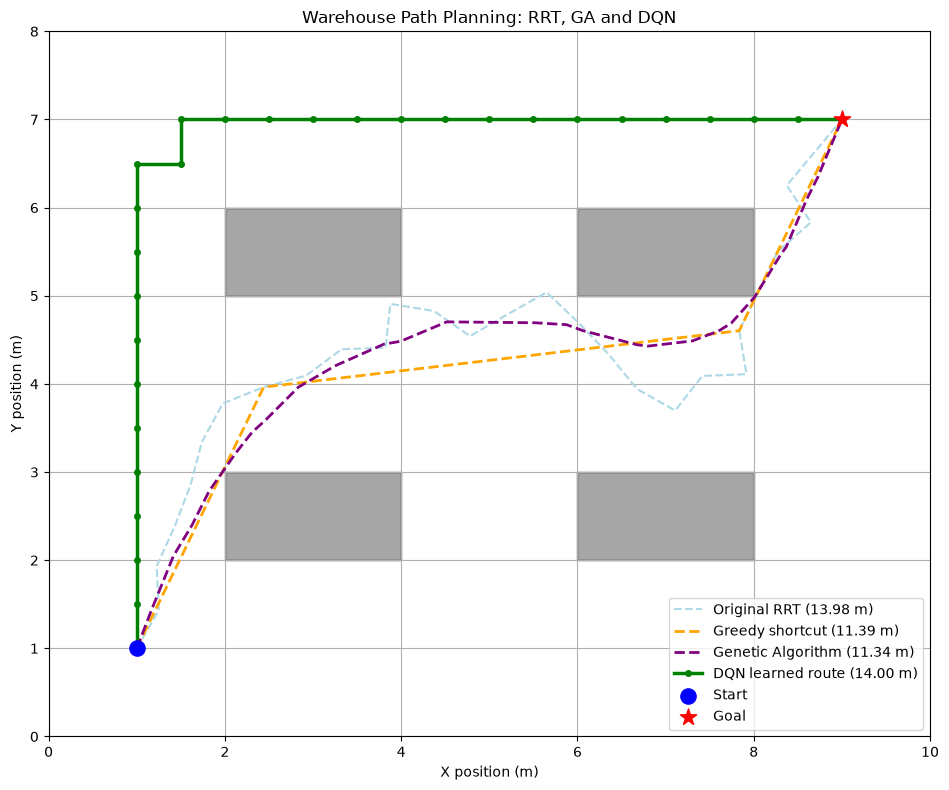

In [29]:
# ============================================================
# LAB 7: DEEP REINFORCEMENT LEARNING
# CELL 50D: POLICY EVALUATION AND PATH COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. EVALUATE THE LEARNED POLICY
# ------------------------------------------------------------

evaluation_state = environment.reset()

evaluation_path = [environment.position.copy()]
evaluation_reward = 0.0
evaluation_success = False
evaluation_collisions = 0

q_network.eval()

for step in range(environment.max_steps):

    # Greedy action selection: no random exploration
    state_tensor = torch.tensor(
        evaluation_state,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        q_values = q_network(state_tensor)

        action = int(
            torch.argmax(q_values).item()
        )

    # Execute the selected action
    (
        evaluation_state,
        reward,
        done,
        info
    ) = environment.step(action)

    evaluation_reward += reward

    if info["collision"]:
        evaluation_collisions += 1

    evaluation_path.append(
        environment.position.copy()
    )

    if done:
        evaluation_success = info["reached_goal"]
        break

q_network.train()

evaluation_path = np.array(evaluation_path)


# ------------------------------------------------------------
# 2. CALCULATE PATH QUALITY
# ------------------------------------------------------------

evaluation_path_length = np.sum(
    np.linalg.norm(
        np.diff(evaluation_path, axis=0),
        axis=1
    )
)

evaluation_path_collision_free = all(
    is_path_collision_free(
        evaluation_path[i],
        evaluation_path[i + 1]
    )
    for i in range(len(evaluation_path) - 1)
)


# ------------------------------------------------------------
# 3. DISPLAY EVALUATION RESULTS
# ------------------------------------------------------------

print("DQN EVALUATION RESULTS")
print("=" * 45)

print("Goal reached:", evaluation_success)
print("Number of steps:", len(evaluation_path) - 1)
print("Path length:", round(evaluation_path_length, 2), "m")
print("Collisions:", evaluation_collisions)
print("Total evaluation reward:", round(evaluation_reward, 2))
print("Path collision-free:", evaluation_path_collision_free)


# ------------------------------------------------------------
# 4. CALCULATE AND COMPARE ALL FOUR PATH LENGTHS
# ------------------------------------------------------------

def calculate_path_length(path):

    path = np.asarray(path, dtype=float)

    return np.sum(
        np.linalg.norm(
            np.diff(path, axis=0),
            axis=1
        )
    )


original_path_length = calculate_path_length(original_positions)

simplified_path_length = calculate_path_length(simplified_positions)

ga_final_length = calculate_path_length(ga_best_path)

evaluation_path_length = calculate_path_length(evaluation_path)


print("\nPATH PLANNING COMPARISON")
print("=" * 55)

print(f"Original RRT:       {original_path_length:.2f} m")
print(f"Greedy shortcut:    {simplified_path_length:.2f} m")
print(f"Genetic Algorithm:  {ga_final_length:.2f} m")

if evaluation_success and evaluation_path_collision_free:
    print(f"DQN learned route:  {evaluation_path_length:.2f} m")
else:
    print("DQN learned route:  No valid successful route")


# ------------------------------------------------------------
# 5. VISUALIZE THE FOUR PLANNING APPROACHES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

ax.set_xlim(0, warehouse_width)
ax.set_ylim(0, warehouse_height)

for obstacle in obstacles:

    x, y, width, height = obstacle

    ax.add_patch(
        Rectangle(
            (x, y),
            width,
            height,
            facecolor="grey",
            edgecolor="black",
            alpha=0.7
        )
    )

ax.plot(
    original_positions[:, 0],
    original_positions[:, 1],
    "--",
    color="lightblue",
    linewidth=1.5,
    label=f"Original RRT ({original_path_length:.2f} m)"
)

ax.plot(
    simplified_positions[:, 0],
    simplified_positions[:, 1],
    "--",
    color="orange",
    linewidth=2,
    label=f"Greedy shortcut ({simplified_path_length:.2f} m)"
)

ga_positions = np.asarray(ga_best_path)

ax.plot(
    ga_positions[:, 0],
    ga_positions[:, 1],
    "--",
    color="purple",
    linewidth=2,
    label=f"Genetic Algorithm ({ga_final_length:.2f} m)"
)

ax.plot(
    evaluation_path[:, 0],
    evaluation_path[:, 1],
    "-o",
    color="green",
    linewidth=2.5,
    markersize=4,
    label=f"DQN learned route ({evaluation_path_length:.2f} m)"
)

ax.scatter(
    start[0], start[1],
    color="blue", s=120, marker="o",
    label="Start", zorder=5
)

ax.scatter(
    goal[0], goal[1],
    color="red", s=150, marker="*",
    label="Goal", zorder=5
)

ax.set_title("Warehouse Path Planning: RRT, GA and DQN")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

## Interpreting the Deep Reinforcement Learning Results

The DQN agent was trained for 2,000 episodes using a Deep Q-Network, experience replay, and a target network.

During training, the agent progressively improved its navigation behaviour. The final 100 training episodes achieved a 100% goal-reaching success rate, with a mean cumulative reward of 89.84.

We then evaluated the learned policy without random exploration. The agent successfully reached the goal while avoiding all obstacles.

### 1. DQN Evaluation Results

| Performance metric | Result |
|---|---:|
| Goal reached | Yes |
| Number of movement steps | 28 |
| Path length | 14.00 m |
| Collisions | 0 |
| Total evaluation reward | 92.00 |
| Path collision-free | Yes |

The DQN agent learned a valid navigation policy for the warehouse environment.

### 2. Comparison of All Four Approaches

| Planning approach | Path length |
|---|---:|
| Original RRT | 13.98 m |
| Greedy shortcutting | 11.39 m |
| Genetic Algorithm | **11.34 m** |
| Deep Q-Network | 14.00 m |

### 3. What Do These Results Tell Us?

**A. RRT successfully discovers a feasible path.**

RRT produced a collision-free path of 13.98 m. However, its exploration-based construction does not necessarily produce an efficient path.

**B. Greedy shortcutting significantly improves path quality.**

Greedy shortcutting reduced the original RRT path length from 13.98 m to 11.39 m.

This demonstrates that relatively simple geometric post-processing can provide substantial improvements.

**C. Genetic Algorithm provides the shortest path in this experiment.**

The GA produced a collision-free path of 11.34 m, improving upon greedy shortcutting by approximately 0.50%.

It achieved the best path length among the four approaches evaluated.

**D. DQN learns successful navigation behaviour, but not necessarily an optimal path.**

The DQN agent reached the goal in 28 movement steps, producing a collision-free path of 14.00 m.

Its path was approximately:
- 0.14% longer than the original RRT path.
- 22.91% longer than the greedy-shortcut path.
- 23.46% longer than the GA path.

The DQN objective was to learn a policy that maximizes cumulative reward, not explicitly to minimize geometric path length.

Consequently, successful navigation does not automatically imply optimal path quality.

### 4. Why Did DQN Produce a Longer Path?

There are several important reasons.

**Discrete action space:** The agent can move only in four directions, with each movement covering 0.5 m. This restricts the paths it can construct to axis-aligned movements.

**Reward-based learning:** The agent learns to maximize cumulative reward based on the reward function. It is not directly solving a geometric path-length minimization problem.

**Fixed training environment:** The agent was trained and evaluated in the same warehouse configuration. Its success does not establish generalization to unfamiliar maps.

**Learning and optimization are different objectives:** A learned policy may consistently reach the goal without discovering the geometrically shortest route.

### 5. Engineering Comparison

The experiment demonstrates different strengths of the four approaches:

| Approach | Main strength | Main limitation |
|---|---|---|
| RRT | Explores the configuration space to find feasible paths | May produce unnecessarily long paths |
| Greedy shortcutting | Simple and effective path improvement | Greedy decisions do not guarantee global optimality |
| Genetic Algorithm | Optimizes waypoint coordinates | Requires iterative population-based optimization |
| DQN | Learns a navigation policy through interaction | Requires training and may not produce optimal paths |

### Key Engineering Takeaway

There is no universally superior path-planning approach.

The appropriate method depends on the application requirements, available computational resources, environment characteristics, and whether the objective is to compute a path or learn a reusable navigation policy.

In this experiment, GA produced the shortest path, while DQN demonstrated successful learning-based navigation.

The distinction between **finding an efficient path** and **learning a navigation policy** is fundamental to understanding classical and learning-based robotics.

---

## Conclusion of Lab 7

In this laboratory, we formulated warehouse navigation as a Markov Decision Process and implemented a Deep Q-Network to learn navigation behaviour.

The agent learned through repeated interaction with the environment, using rewards, experience replay, and a target network.

The final evaluation demonstrated that the learned policy could reach the goal without collisions.

Together, Labs 6 and 7 introduced three complementary approaches to autonomous robot navigation:

1. Sampling-based planning using RRT.
2. Evolutionary path optimization using Genetic Algorithms.
3. Learning-based navigation using Deep Reinforcement Learning.

These approaches provide different ways of addressing the same fundamental robotics problem: enabling an autonomous mobile robot to navigate safely and effectively through an environment containing obstacles.